

```
# Esto tiene formato de código
```

**Avance 1 Proyecto dataset anime**

---



**Celda 1: Carga de Datos, Limpieza y Creación de Variable Objetivo**

In [ ]:
# --- CELDA 1: Carga Directa desde Kaggle, Limpieza y Creación de Variable Objetivo ---

# 1. Instalar la librería oficial de Kaggle (si no está instalada en Colab)
!pip install -q kagglehub

import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo gráfico
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 2. Descargar el dataset directamente desde Kaggle usando su identificador
# URL: https://www.kaggle.com/datasets/patelris/anime-and-manga-dataset-2026
path_dataset = kagglehub.dataset_download("patelris/anime-and-manga-dataset-2026")

# 3. Localizar el CSV de ANIME. El dataset trae también un CSV de manga, que se descarta.
ARCHIVO_ANIME = None   # opcional: escribe aquí el nombre exacto del CSV de anime si la detección automática falla

archivos_csv = sorted(f for f in os.listdir(path_dataset) if f.endswith('.csv'))
print("Archivos CSV en el dataset:", archivos_csv)
if ARCHIVO_ANIME is None:
    candidatos = [f for f in archivos_csv if 'anime' in f.lower() and 'manga' not in f.lower()]
    if not candidatos:
        raise FileNotFoundError(f"No encontré un CSV de anime entre {archivos_csv}. "
                                "Escribe el nombre correcto en ARCHIVO_ANIME.")
    ARCHIVO_ANIME = candidatos[0]

df = pd.read_csv(os.path.join(path_dataset, ARCHIVO_ANIME))

# Verificación: un CSV de anime tiene 'episodes'; uno de manga tiene 'chapters' / 'volumes'
if 'episodes' not in df.columns and {'chapters', 'volumes'} & set(df.columns):
    raise ValueError(f"'{ARCHIVO_ANIME}' parece ser de MANGA (tiene chapters/volumes y no episodes). "
                     "Revisa ARCHIVO_ANIME.")
print(f"Dataset cargado exitosamente desde Kaggle: '{ARCHIVO_ANIME}'")
print(f"Dimensiones originales: {df.shape[0]} filas, {df.shape[1]} columnas")

# 4. Tratamiento de nulos en la variable objetivo original (score)
# Se eliminan los animes no calificados
df_clean = df.dropna(subset=['score']).copy()

# 5. Creación de la Variable Objetivo Categórica (Clasificación)
def categorizar_exito(s):
    if s >= 7.0:
        return 'Alto (Éxito)'
    elif s >= 5.5:
        return 'Promedio'
    else:
        return 'Bajo'

df_clean['categoria_exito'] = df_clean['score'].apply(categorizar_exito)
print(f"Registros procesados y listos para el análisis: {len(df_clean)} animes")

100%|██████████| 24.1M/24.1M [00:02<00:00, 10.1MB/s]

Extracting files...


Archivos CSV en el dataset: ['anime_dataset.csv', 'manga_dataset.csv']
Dataset cargado exitosamente desde Kaggle: 'anime_dataset.csv'
Dimensiones originales: 30075 filas, 29 columnas
Registros procesados y listos para el análisis: 19892 animes


**Celda 2: Selección de Variables (Al superar las 20 características)**

=== CORRELACIÓN DE CADA VARIABLE CON LA VARIABLE OBJETIVO (score) ===
score         1.000000
members       0.374000
scored_by     0.336414
favorites     0.221955
episodes      0.095389
year          0.009847
popularity   -0.646544
rank         -0.974556
Name: score, dtype: float64


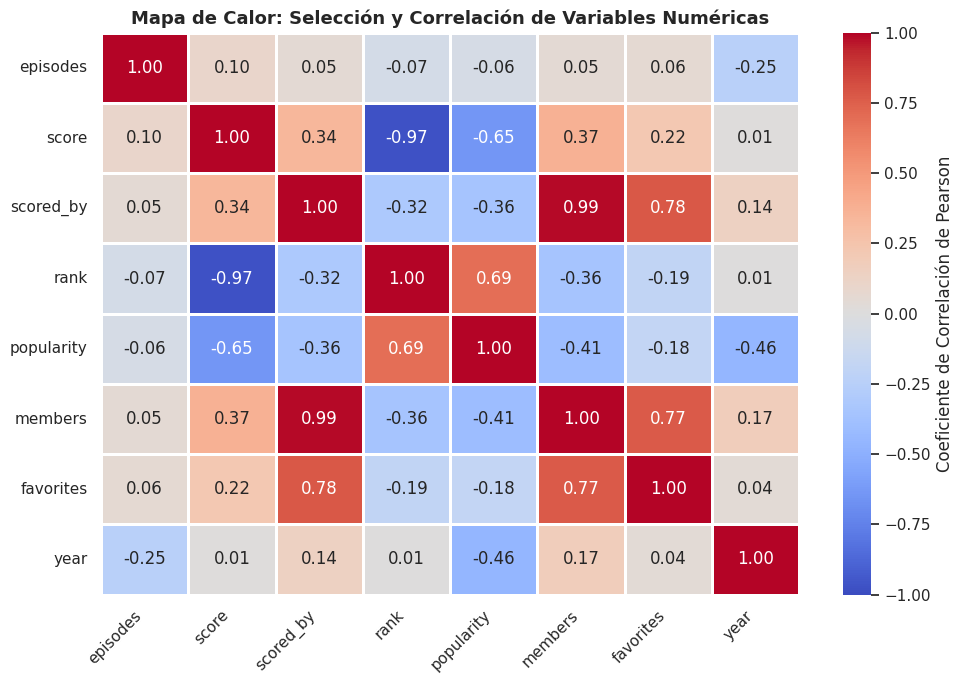

In [ ]:
# --- CELDA 2: Selección de Variables y Mapa de Calor (Heatmap) ---

# 1. Seleccionar variables numéricas excluyendo identificadores sin valor predictivo (como 'mal_id')
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
cols_para_correlacion = [col for col in numeric_cols if col != 'mal_id']

# 2. Calcular la matriz de correlación de Pearson
matriz_correlacion = df_clean[cols_para_correlacion].corr()

# 3. Imprimir la relación directa con la variable objetivo 'score'
print("=== CORRELACIÓN DE CADA VARIABLE CON LA VARIABLE OBJETIVO (score) ===")
print(matriz_correlacion['score'].sort_values(ascending=False))

# 4. Generación del Mapa de Calor (Heatmap)
plt.figure(figsize=(10, 7))
sns.heatmap(
    matriz_correlacion,
    annot=True,            # Muestra el valor numérico de correlación en cada celda
    fmt=".2f",             # Formato con 2 decimales
    cmap='coolwarm',       # Paleta divergente (rojo=correlación positiva, azul=negativa)
    vmin=-1,
    vmax=1,
    linewidths=0.8,
    cbar_kws={'label': 'Coeficiente de Correlación de Pearson'}
)

plt.title('Mapa de Calor: Selección y Correlación de Variables Numéricas', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Celda 3: Análisis de Variables Categóricas (Frecuencia Total y Porcentaje)**

=== REPORTE: VARIABLE OBJETIVO (categoria_exito) ===
- Categoria 'Promedio': 11,586 casos (58.24%)
- Categoria 'Alto (Éxito)': 5,425 casos (27.27%)
- Categoria 'Bajo': 2,881 casos (14.48%)

=== REPORTE: VARIABLE CATEGÓRICA (type) ===
- Formato 'TV': 5,377 casos (27.03%)
- Formato 'OVA': 3,575 casos (17.97%)
- Formato 'Movie': 2,998 casos (15.07%)
- Formato 'Music': 2,593 casos (13.04%)
- Formato 'ONA': 2,590 casos (13.02%)


/tmp/ipykernel_884/4222930760.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='categoria_exito', ax=axes[0], palette='Set2', order=['Bajo', 'Promedio', 'Alto (Éxito)'])
/tmp/ipykernel_884/4222930760.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='type', ax=axes[1], palette='Set3', order=frec_type.index[:5])


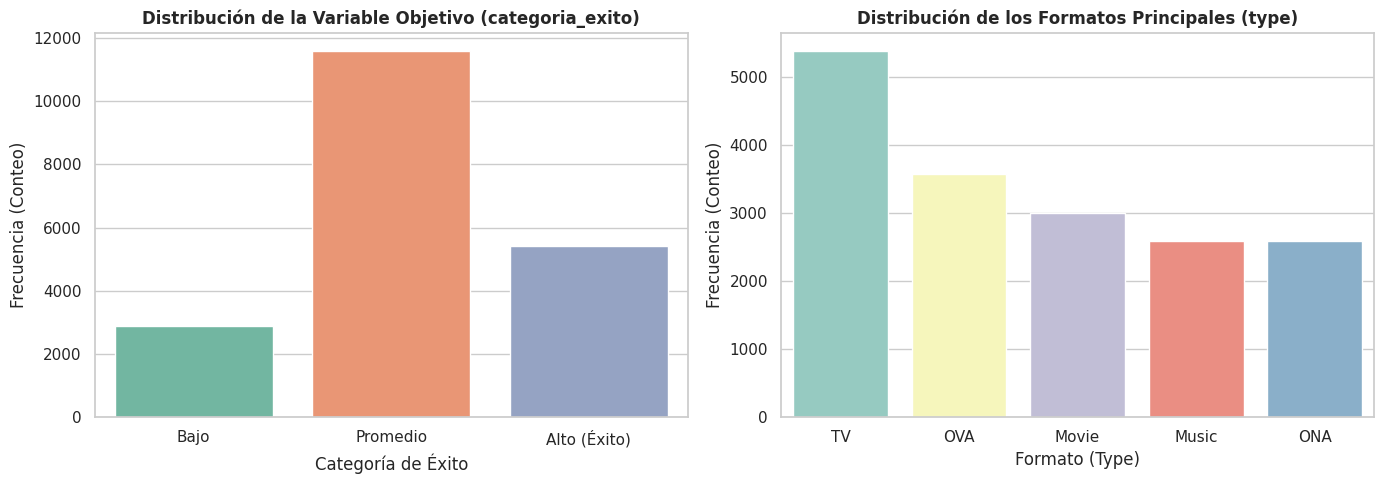

In [ ]:
# --- A) Variable Objetivo Categórica: 'categoria_exito' ---
frec_obj = df_clean['categoria_exito'].value_counts()
pct_obj = df_clean['categoria_exito'].value_counts(normalize=True) * 100

print("=== REPORTE: VARIABLE OBJETIVO (categoria_exito) ===")
for cat in frec_obj.index:
    print(f"- Categoria '{cat}': {frec_obj[cat]:,} casos ({pct_obj[cat]:.2f}%)")

# --- B) Variable Categórica Predictora: 'type' (Tipo de Formato) ---
frec_type = df_clean['type'].value_counts()
pct_type = df_clean['type'].value_counts(normalize=True) * 100

print("\n=== REPORTE: VARIABLE CATEGÓRICA (type) ===")
for t in frec_type.index[:5]: # Top 5 formatos
    print(f"- Formato '{t}': {frec_type[t]:,} casos ({pct_type[t]:.2f}%)")

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico Variable Objetivo
sns.countplot(data=df_clean, x='categoria_exito', ax=axes[0], palette='Set2', order=['Bajo', 'Promedio', 'Alto (Éxito)'])
axes[0].set_title('Distribución de la Variable Objetivo (categoria_exito)', fontweight='bold')
axes[0].set_xlabel('Categoría de Éxito')
axes[0].set_ylabel('Frecuencia (Conteo)')

# Gráfico Formato
sns.countplot(data=df_clean, x='type', ax=axes[1], palette='Set3', order=frec_type.index[:5])
axes[1].set_title('Distribución de los Formatos Principales (type)', fontweight='bold')
axes[1].set_xlabel('Formato (Type)')
axes[1].set_ylabel('Frecuencia (Conteo)')

plt.tight_layout()
plt.show()

**Celda 4: Análisis de Variable Numérica Simétrica (Media y Desviación Estándar)**

=== REPORTE SEGÚN ESTÁNDAR DE LA RÚBRICA ===
"La calificación promedio (score) es de 6.43 ± 0.89 puntos."


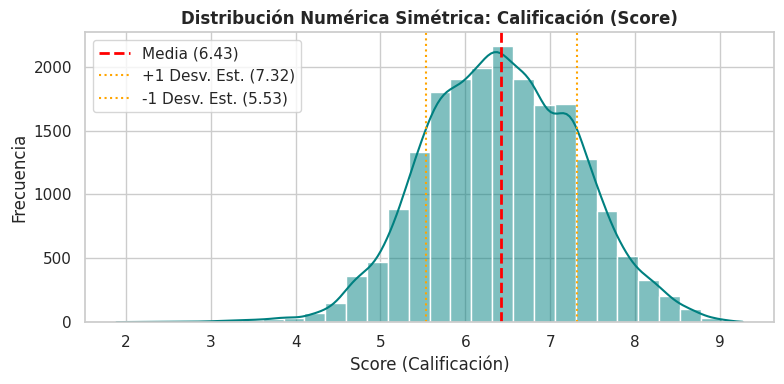

In [ ]:
# Variable: 'score' (Calificación)
media_score = df_clean['score'].mean()
std_score = df_clean['score'].std()

print("=== REPORTE SEGÚN ESTÁNDAR DE LA RÚBRICA ===")
print(f'"La calificación promedio (score) es de {media_score:.2f} ± {std_score:.2f} puntos."')

# Visualización de Distribución Simétrica
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['score'], kde=True, color='teal', bins=30)
plt.axvline(media_score, color='red', linestyle='--', linewidth=2, label=f'Media ({media_score:.2f})')
plt.axvline(media_score + std_score, color='orange', linestyle=':', label=f'+1 Desv. Est. ({media_score + std_score:.2f})')
plt.axvline(media_score - std_score, color='orange', linestyle=':', label=f'-1 Desv. Est. ({media_score - std_score:.2f})')

plt.title('Distribución Numérica Simétrica: Calificación (Score)', fontsize=12, fontweight='bold')
plt.xlabel('Score (Calificación)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

**Celda 5: Análisis de Variable Numérica Asimétrica (Mediana y Rango Intercuartil - IQR)**

=== REPORTE SEGÚN ESTÁNDAR DE LA RÚBRICA ===
"La variable members tiene una mediana de 4,188 usuarios y un rango intercuartil (IQR) de 24,028 (984 - 25,012)."


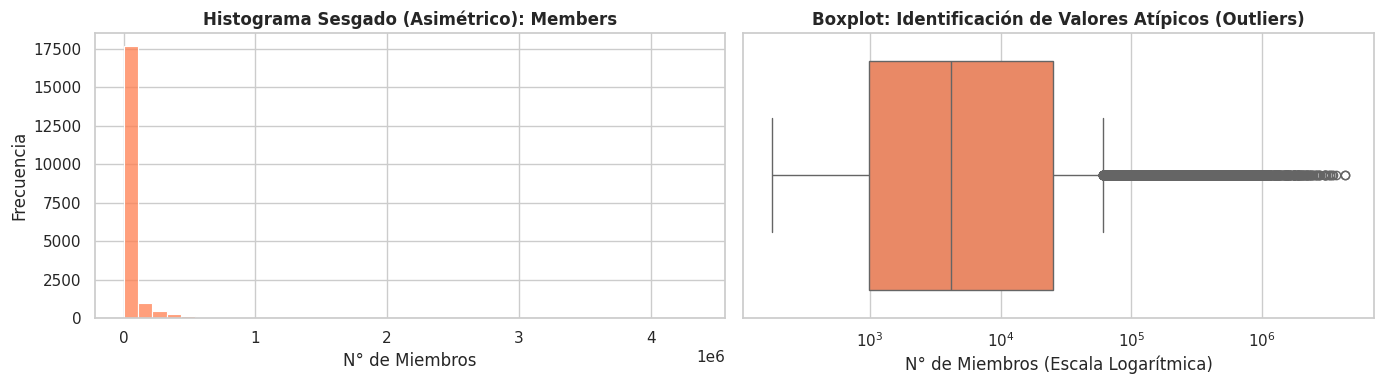

In [ ]:
# Variable: 'members' (Número de Miembros / Popularidad)
mediana_mem = df_clean['members'].median()
q25_mem = df_clean['members'].quantile(0.25)
q75_mem = df_clean['members'].quantile(0.75)
iqr_mem = q75_mem - q25_mem

print("=== REPORTE SEGÚN ESTÁNDAR DE LA RÚBRICA ===")
print(f'"La variable members tiene una mediana de {mediana_mem:,.0f} usuarios y un rango intercuartil (IQR) de {iqr_mem:,.0f} ({q25_mem:,.0f} - {q75_mem:,.0f})."')

# Visualización de Distribución Asimétrica
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma sesgado a la derecha
sns.histplot(df_clean['members'], kde=False, color='coral', bins=40, ax=axes[0])
axes[0].set_title('Histograma Sesgado (Asimétrico): Members', fontweight='bold')
axes[0].set_xlabel('N° de Miembros')
axes[0].set_ylabel('Frecuencia')

# Boxplot con Outliers
sns.boxplot(x=df_clean['members'], ax=axes[1], color='coral')
axes[1].set_title('Boxplot: Identificación de Valores Atípicos (Outliers)', fontweight='bold')
axes[1].set_xlabel('N° de Miembros (Escala Logarítmica)')
axes[1].set_xscale('log') # Escala logarítmica para apreciar la caja y los outliers

plt.tight_layout()
plt.show()

---

# **Avance 2 — Modelos de predicción y comparación**

Se aplican cuatro modelos de clasificación para predecir `categoria_exito` (**Bajo / Promedio / Alto (Éxito)**): **Gaussian Naive Bayes (GNB), Decision Tree (DT), Random Forest (RF) y SVM**.

- Partición: **60% train / 20% validación / 20% test**. El test solo se usa al final.
- Los hiperparámetros se eligen con **validación**; la validación cruzada (5 folds) se hace solo sobre `train`.
- Como son 3 clases, Precision / Recall / F1 se calculan con promedio **macro** (todas las clases pesan igual, incluida la clase menos frecuente).
- Criterio de selección del mejor modelo: **F1 macro en validación**.

**Celda 6: Variables predictoras, preprocesamiento y partición Train / Validación / Test**

In [ ]:
# --- CELDA 6: Variables predictoras, preprocesamiento y partición ---
import time
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             precision_recall_fscore_support, ConfusionMatrixDisplay,
                             classification_report)

SEED = 21
ORDEN_CLASES = ['Bajo', 'Promedio', 'Alto (Éxito)']

# IMPORTANTE: 'rank' se calcula a partir de 'score' (correlación muy alta, ver el heatmap), que es justo lo que
# define la variable objetivo. Usarlo sería "fuga de información" (data leakage), así que se
# excluye. Cámbialo a True solo si quieres ver lo que ocurre (las métricas se disparan).
USAR_RANK = False

cand_num = ['members', 'scored_by', 'favorites', 'episodes', 'year', 'popularity']
if USAR_RANK:
    cand_num.append('rank')
cols_num = [c for c in cand_num if c in df_clean.columns]
cols_log = [c for c in cols_num if c != 'year']     # variables muy asimétricas -> log1p
cols_lin = [c for c in cols_num if c == 'year']
cols_cat = [c for c in ['type', 'source', 'rating', 'season']
            if c in df_clean.columns
            and not pd.api.types.is_numeric_dtype(df_clean[c])
            and df_clean[c].nunique() <= 20]

print("Variables numéricas :", cols_num)
print("Variables categóricas:", cols_cat)

X = df_clean[cols_num + cols_cat].copy()
for c in cols_cat:
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
y = df_clean['categoria_exito'].copy()

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
print(f"\nTrain: {len(y_train)} | Validación: {len(y_val)} | Test: {len(y_test)}")
display(y_train.value_counts().reindex(ORDEN_CLASES).rename('Train: muestras por clase'))


def log1p_pos(Z):
    return np.log1p(np.clip(Z, 0, None))


def make_prep(escalar=False):
    """Imputa nulos, aplica log1p a variables asimétricas, one-hot a categóricas
    y (opcional) estandariza. Se ajusta solo con los datos que recibe en fit."""
    pasos_log = [SimpleImputer(strategy='median'),
                 FunctionTransformer(log1p_pos, feature_names_out='one-to-one')]
    pasos_lin = [SimpleImputer(strategy='median')]
    if escalar:
        pasos_log.append(StandardScaler())
        pasos_lin.append(StandardScaler())
    trans = []
    if cols_log:
        trans.append(('log', make_pipeline(*pasos_log), cols_log))
    if cols_lin:
        trans.append(('lin', make_pipeline(*pasos_lin), cols_lin))
    if cols_cat:
        trans.append(('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                           OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
                      cols_cat))
    return ColumnTransformer(trans, verbose_feature_names_out=False)


def construir(clf, escalar=False):
    return Pipeline([('prep', make_prep(escalar)), ('clf', clf)])


Variables numéricas : ['members', 'scored_by', 'favorites', 'episodes', 'year', 'popularity']
Variables categóricas: ['type', 'source', 'rating', 'season']

Train: 11934 | Validación: 3979 | Test: 3979


,Train: muestras por clase
categoria_exito,
Bajo,1729
Promedio,6950
Alto (Éxito),3255


**Celda 7: Funciones auxiliares (métricas, tiempos, matrices de confusión y validación cruzada)**

In [ ]:
# --- CELDA 7: Funciones auxiliares ---
modelos, filas_val, preds_val, cv_resultados = {}, {}, {}, {}


def metric_row(nombre, y_true, y_pred):
    return {'Modelo': nombre,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision (macro)': precision_score(y_true, y_pred, average='macro', labels=ORDEN_CLASES, zero_division=0),
            'Recall (macro)': recall_score(y_true, y_pred, average='macro', labels=ORDEN_CLASES, zero_division=0),
            'F1 (macro)': f1_score(y_true, y_pred, average='macro', labels=ORDEN_CLASES, zero_division=0)}


def entrenar_y_medir(modelo, nombre):
    """Entrena con train y mide en validación (y también en train, para detectar sobreajuste)."""
    t0 = time.time()
    modelo.fit(X_train, y_train)
    t_fit = time.time() - t0
    p_tr, p_val = modelo.predict(X_train), modelo.predict(X_val)
    fila = metric_row(nombre, y_val, p_val)
    fila['Accuracy train'] = accuracy_score(y_train, p_tr)
    fila['F1 train (macro)'] = f1_score(y_train, p_tr, average='macro', labels=ORDEN_CLASES, zero_division=0)
    fila['Tiempo entrenamiento (s)'] = t_fit
    return fila, p_val


def plot_cm(y_true, y_pred, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=ORDEN_CLASES, cmap='Blues',
                                            ax=axes[0], colorbar=False)
    axes[0].set_title(f'{titulo}\nConteos')
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=ORDEN_CLASES, cmap='Blues',
                                            normalize='true', values_format='.2f', ax=axes[1], colorbar=False)
    axes[1].set_title(f'{titulo}\n% por clase real (recall de cada clase)')
    for ax in axes:
        ax.grid(False)
        ax.tick_params(axis='x', rotation=15)
    plt.tight_layout()
    plt.show()


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))
scoring_cv = {'Accuracy': 'accuracy', 'Precision': 'precision_macro',
              'Recall': 'recall_macro', 'F1': 'f1_macro'}


def correr_cv(nombre, modelo):
    """Validación cruzada estratificada (mismos 5 folds para todos los modelos), solo sobre train."""
    s = cross_validate(modelo, X_train, y_train, cv=cv_splits, scoring=scoring_cv)
    cv_resultados[nombre] = s
    for m in ['Accuracy', 'F1']:
        v = s[f'test_{m}']
        print(f"CV {nombre} | {m}: {np.mean(v):.3f} (+/- {np.std(v):.3f})")


def nombres_features(modelo):
    return list(modelo.named_steps['prep'].get_feature_names_out())


## **1. Gaussian Naive Bayes — punto de partida**

Modelo probabilístico simple que asume que las variables son independientes y gaussianas dentro de cada clase. Sirve como referencia: cualquier modelo más complejo debería superarlo para justificar su costo.

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Accuracy train,F1 train (macro),Tiempo entrenamiento (s)
Modelo,,,,,,,
GNB,0.445,0.525,0.613,0.441,0.453,0.449,0.169


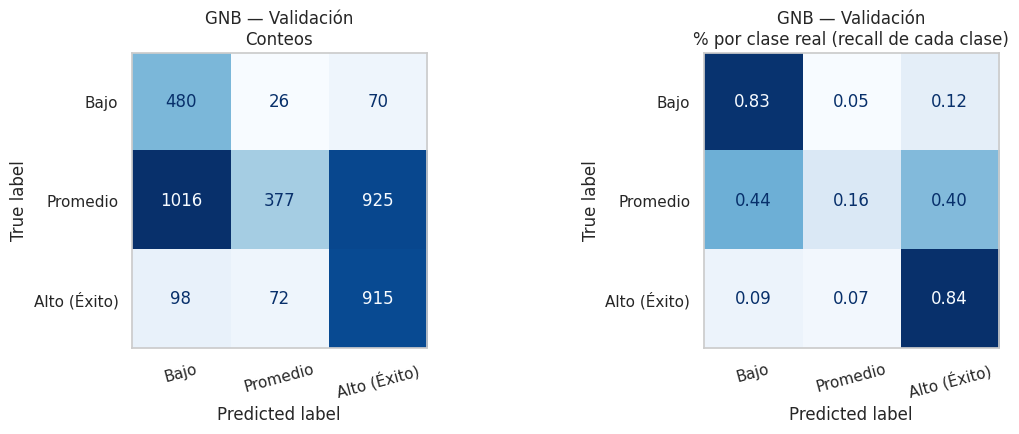

CV GNB | Accuracy: 0.441 (+/- 0.029)
CV GNB | F1: 0.438 (+/- 0.028)


In [ ]:
# --- CELDA 8: Gaussian Naive Bayes ---
gnb = construir(GaussianNB())
fila, pred = entrenar_y_medir(gnb, 'GNB')
modelos['GNB'], filas_val['GNB'], preds_val['GNB'] = gnb, fila, pred

display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_cm(y_val, pred, 'GNB — Validación')
correr_cv('GNB', construir(GaussianNB()))


## **2. Decision Tree**

Un árbol aprende reglas `si variable ≤ umbral`. `max_depth` controla su complejidad: poco profundo → puede **subajustar**; muy profundo → memoriza el entrenamiento (**sobreajuste**). Se prueban varias profundidades comparando **train vs. validación**.

,max_depth,Accuracy train,Accuracy val,F1 train (macro),F1 val (macro)
0,1,0.682,0.678,0.478,0.474
1,2,0.682,0.678,0.478,0.474
2,3,0.690,0.689,0.480,0.478
3,4,0.694,0.688,0.484,0.477
4,6,0.722,0.704,0.592,0.562
5,8,0.753,0.717,0.635,0.584
6,12,0.834,0.706,0.781,0.635
7,None,1.000,0.666,1.000,0.612



Mejor profundidad según F1 macro de validación: max_depth=12


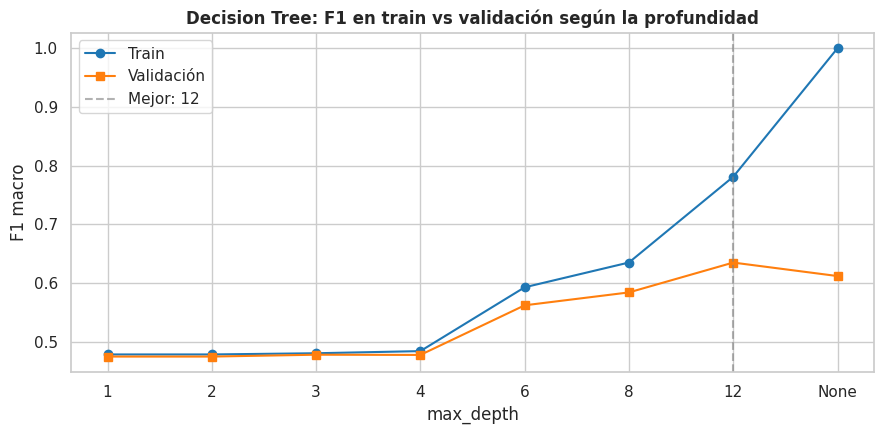

In [ ]:
# --- CELDA 9: Decision Tree — efecto de la profundidad (train vs validación) ---
profundidades = [1, 2, 3, 4, 6, 8, 12, None]
filas = []
for d in profundidades:
    f, _ = entrenar_y_medir(construir(DecisionTreeClassifier(max_depth=d, random_state=SEED)), 'DT')
    f['max_depth'] = str(d)
    filas.append(f)
df_depth = pd.DataFrame(filas)
display(df_depth[['max_depth', 'Accuracy train', 'Accuracy', 'F1 train (macro)', 'F1 (macro)']]
        .rename(columns={'Accuracy': 'Accuracy val', 'F1 (macro)': 'F1 val (macro)'}).round(3))

pos = int(np.argmax(df_depth['F1 (macro)'].values))      # en empate gana la más simple (menor profundidad)
best_depth = profundidades[pos]
print(f"\nMejor profundidad según F1 macro de validación: max_depth={best_depth}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df_depth['max_depth'], df_depth['F1 train (macro)'], 'o-', label='Train', color='tab:blue')
ax.plot(df_depth['max_depth'], df_depth['F1 (macro)'], 's-', label='Validación', color='tab:orange')
ax.axvline(pos, color='gray', linestyle='--', alpha=.6, label=f'Mejor: {best_depth}')
ax.set_xlabel('max_depth'); ax.set_ylabel('F1 macro')
ax.set_title('Decision Tree: F1 en train vs validación según la profundidad', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Accuracy train,F1 train (macro),Tiempo entrenamiento (s)
Modelo,,,,,,,
DT,0.706,0.661,0.621,0.635,0.834,0.781,0.259


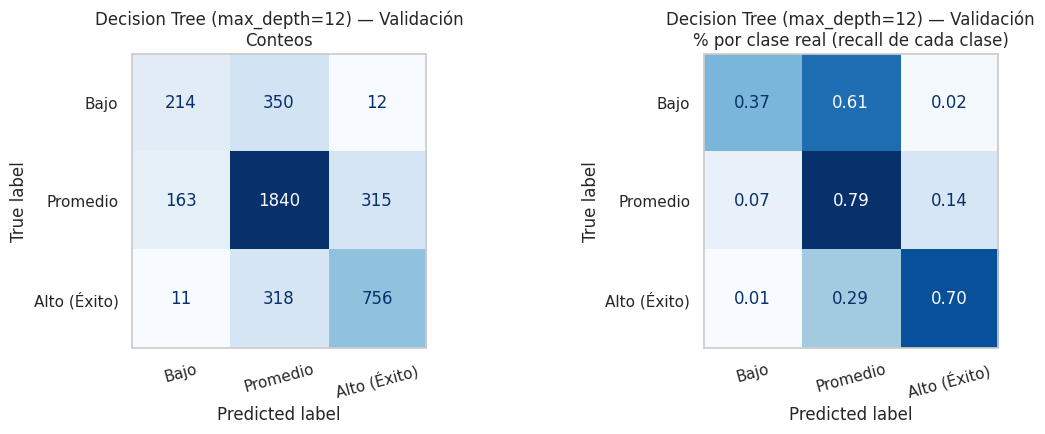

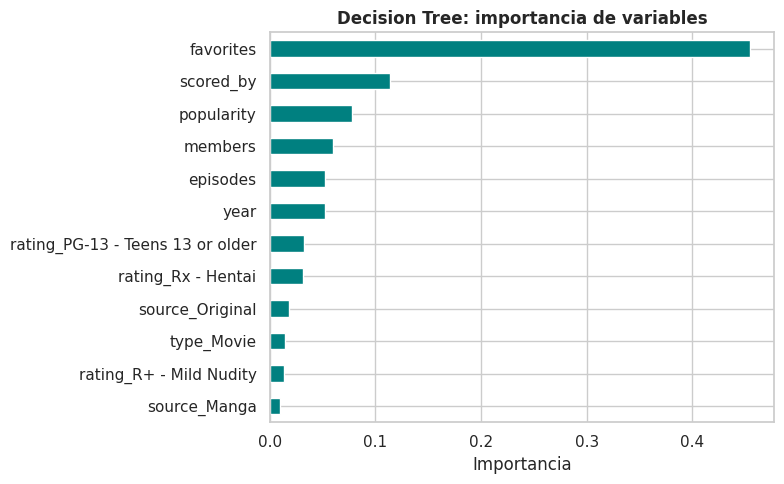

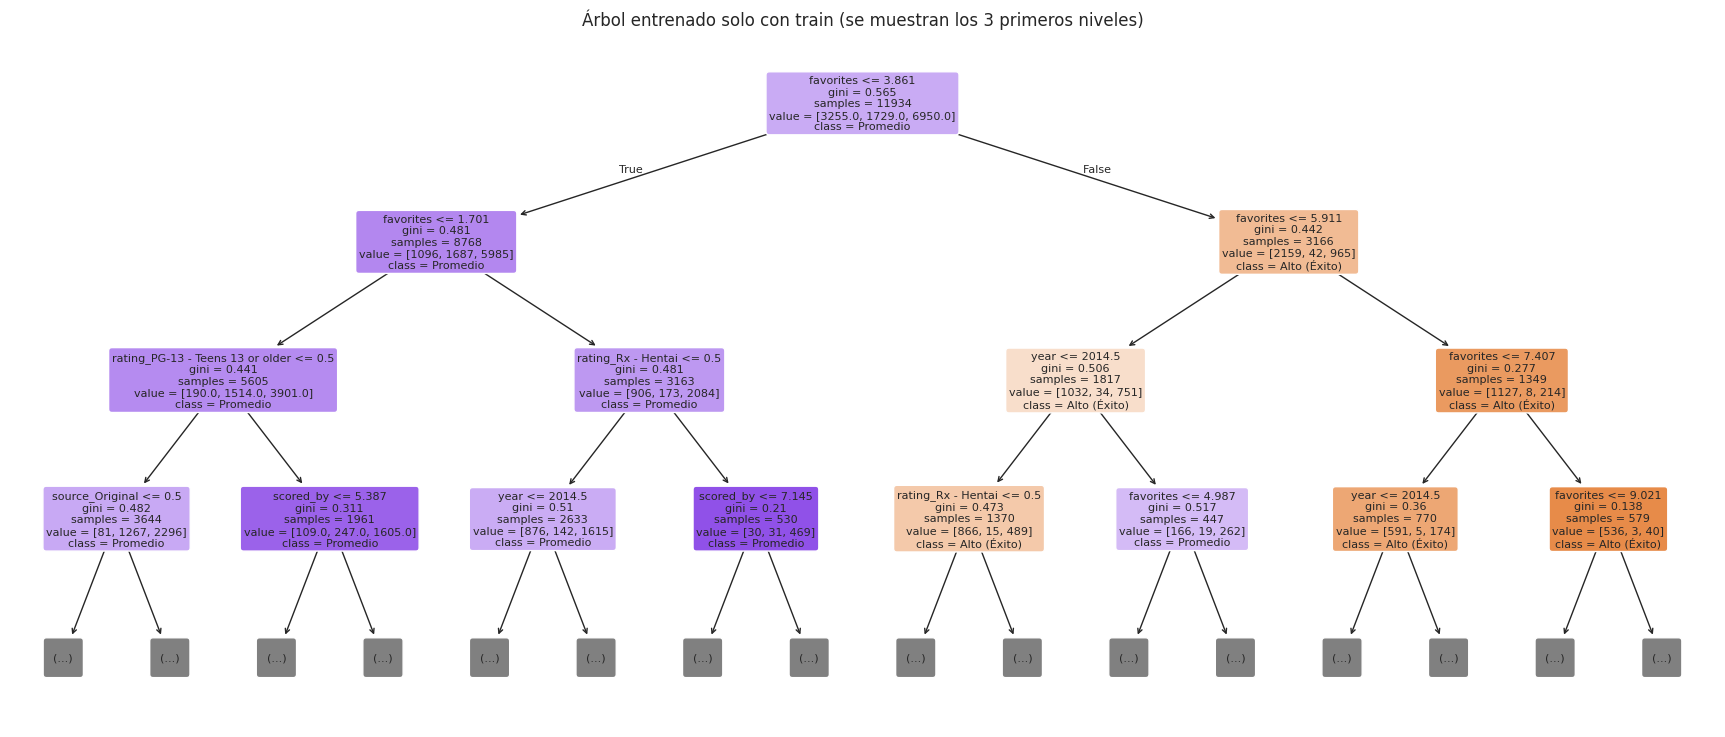

CV DT | Accuracy: 0.702 (+/- 0.011)
CV DT | F1: 0.628 (+/- 0.016)


In [ ]:
# --- CELDA 10: Decision Tree final (mejor profundidad): matriz de confusión, importancias, árbol y CV ---
dt = construir(DecisionTreeClassifier(max_depth=best_depth, random_state=SEED))
fila, pred = entrenar_y_medir(dt, 'DT')
modelos['DT'], filas_val['DT'], preds_val['DT'] = dt, fila, pred
display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_cm(y_val, pred, f'Decision Tree (max_depth={best_depth}) — Validación')

# Importancia de variables (describe el uso de cada variable en ESTE árbol; no implica causalidad)
imp = pd.Series(dt.named_steps['clf'].feature_importances_, index=nombres_features(dt)).sort_values()
plt.figure(figsize=(8, 5))
imp.tail(12).plot(kind='barh', color='teal')
plt.title('Decision Tree: importancia de variables', fontweight='bold')
plt.xlabel('Importancia'); plt.tight_layout(); plt.show()

# Visualización de los primeros niveles del árbol
plt.figure(figsize=(22, 9))
plot_tree(dt.named_steps['clf'], max_depth=3, feature_names=nombres_features(dt),
          class_names=list(dt.named_steps['clf'].classes_), filled=True, rounded=True, fontsize=8)
plt.title('Árbol entrenado solo con train (se muestran los 3 primeros niveles)')
plt.show()

correr_cv('DT', construir(DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)))


## **3. Random Forest**

Combina muchos árboles entrenados con muestras bootstrap y subconjuntos aleatorios de variables; promedia sus votos, lo que reduce la varianza de un árbol individual. Se explora `n_estimators` (número de árboles) midiendo también el **tiempo de entrenamiento**.

,n_estimators,F1 train (macro),F1 val (macro),Accuracy val,Tiempo entrenamiento (s)
0,10,0.982,0.668,0.719,0.694
1,50,0.999,0.672,0.737,1.850
2,100,1.000,0.677,0.741,4.273
3,200,1.000,0.680,0.744,8.540



Mejor n_estimators según F1 macro de validación: 200


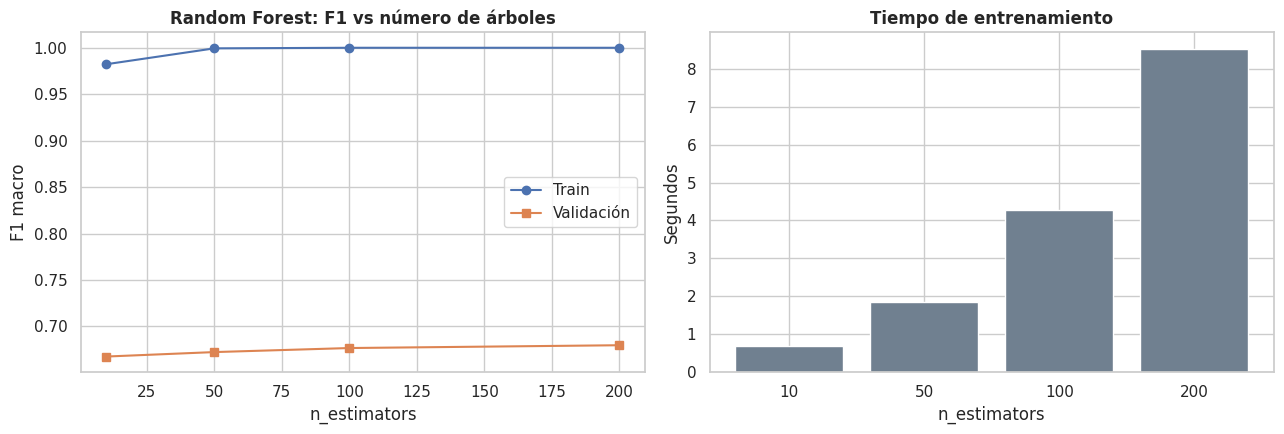

In [ ]:
# --- CELDA 11: Random Forest — efecto de n_estimators (rendimiento y tiempo) ---
n_trees = [10, 50, 100, 200]
filas = []
for n in n_trees:
    f, _ = entrenar_y_medir(construir(RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1)), 'RF')
    f['n_estimators'] = n
    filas.append(f)
df_rf = pd.DataFrame(filas)
display(df_rf[['n_estimators', 'F1 train (macro)', 'F1 (macro)', 'Accuracy', 'Tiempo entrenamiento (s)']]
        .rename(columns={'F1 (macro)': 'F1 val (macro)', 'Accuracy': 'Accuracy val'}).round(3))

pos = int(np.argmax(df_rf['F1 (macro)'].values))          # en empate gana el bosque más pequeño
best_n = n_trees[pos]
print(f"\nMejor n_estimators según F1 macro de validación: {best_n}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df_rf['n_estimators'], df_rf['F1 train (macro)'], 'o-', label='Train')
axes[0].plot(df_rf['n_estimators'], df_rf['F1 (macro)'], 's-', label='Validación')
axes[0].set_xlabel('n_estimators'); axes[0].set_ylabel('F1 macro'); axes[0].legend()
axes[0].set_title('Random Forest: F1 vs número de árboles', fontweight='bold')
axes[1].bar(df_rf['n_estimators'].astype(str), df_rf['Tiempo entrenamiento (s)'], color='slategray')
axes[1].set_xlabel('n_estimators'); axes[1].set_ylabel('Segundos')
axes[1].set_title('Tiempo de entrenamiento', fontweight='bold')
plt.tight_layout(); plt.show()


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Accuracy train,F1 train (macro),Tiempo entrenamiento (s)
Modelo,,,,,,,
RF,0.744,0.715,0.661,0.68,1.0,1.0,9.27


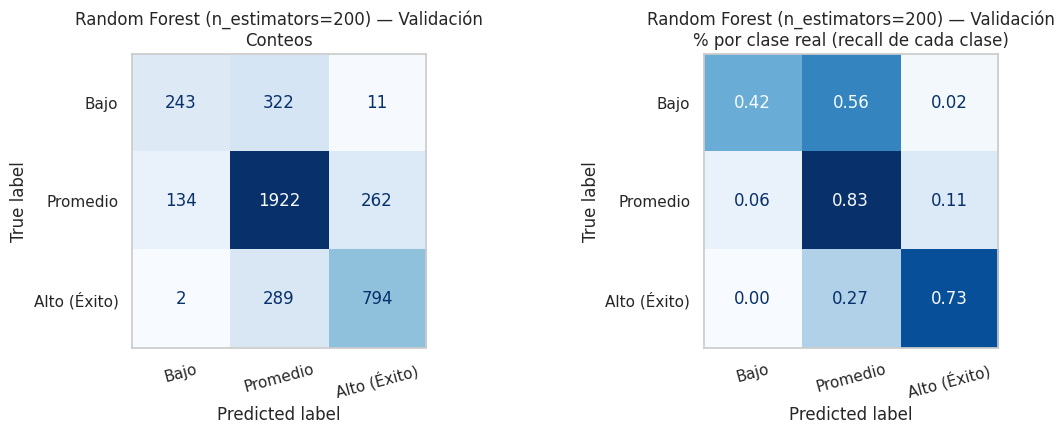

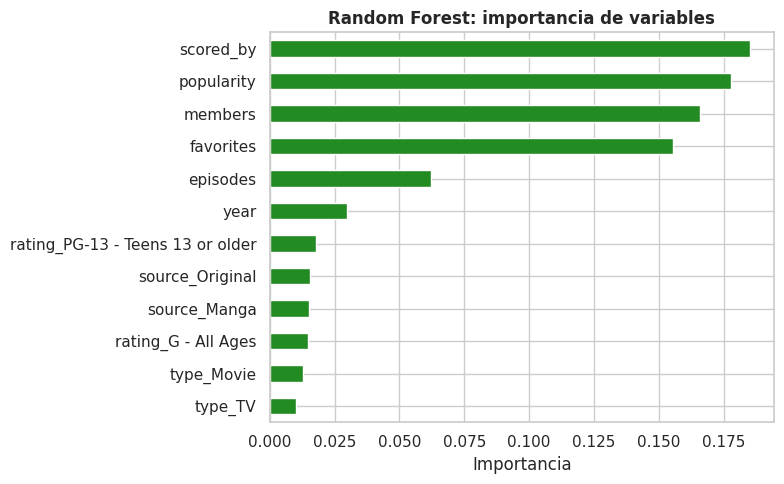

CV RF | Accuracy: 0.748 (+/- 0.009)
CV RF | F1: 0.681 (+/- 0.012)


In [ ]:
# --- CELDA 12: Random Forest final: matriz de confusión, importancias y CV ---
rf = construir(RandomForestClassifier(n_estimators=best_n, random_state=SEED, n_jobs=-1))
fila, pred = entrenar_y_medir(rf, 'RF')
modelos['RF'], filas_val['RF'], preds_val['RF'] = rf, fila, pred
display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_cm(y_val, pred, f'Random Forest (n_estimators={best_n}) — Validación')

imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=nombres_features(rf)).sort_values()
plt.figure(figsize=(8, 5))
imp.tail(12).plot(kind='barh', color='forestgreen')
plt.title('Random Forest: importancia de variables', fontweight='bold')
plt.xlabel('Importancia'); plt.tight_layout(); plt.show()

correr_cv('RF', construir(RandomForestClassifier(n_estimators=best_n, random_state=SEED, n_jobs=-1)))


## **4. Support Vector Machine (SVM)**

Busca una frontera que maximice el margen entre clases. Con kernel RBF puede modelar fronteras no lineales. Es **sensible a la escala** de las variables, por eso se usa un `Pipeline` con `StandardScaler` (se ajusta solo con los datos de entrenamiento de cada fit / fold). Se compara con y sin escalado y se prueban distintos valores de `C`.

> ⏱️ SVM es el modelo más lento de este notebook; con muchos datos esta parte puede tardar unos minutos.

,Configuración,F1 train (macro),F1 val (macro),Accuracy val,Tiempo entrenamiento (s)
0,Sin escalado,0.693,0.666,0.750,9.200
1,Con StandardScaler,0.671,0.649,0.737,7.557


,C,F1 train (macro),F1 val (macro),Accuracy val,Tiempo entrenamiento (s)
0,0.1,0.502,0.489,0.699,11.079
1,1.0,0.672,0.650,0.737,8.691
2,10.0,0.723,0.677,0.754,8.379



Mejor C según F1 macro de validación: C=10


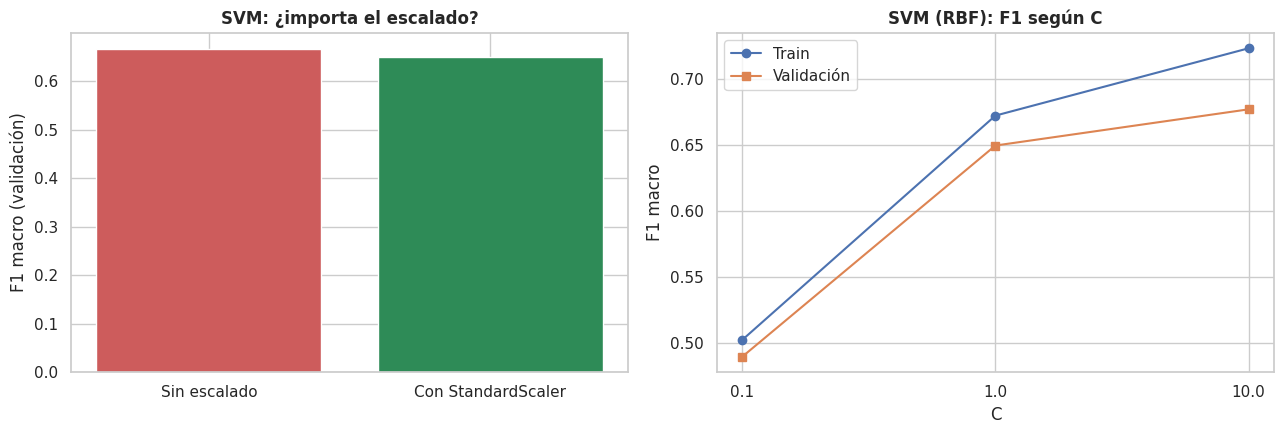

In [ ]:
# --- CELDA 13: SVM — con vs sin escalado, y efecto de C ---
# a) Con y sin StandardScaler (gamma fija = 0.1 en ambos, para que la comparación sea justa)
filas = []
for escalar in [False, True]:
    f, _ = entrenar_y_medir(construir(SVC(kernel='rbf', C=1, gamma=0.1), escalar=escalar), 'SVM')
    f['Configuración'] = 'Con StandardScaler' if escalar else 'Sin escalado'
    filas.append(f)
df_scale = pd.DataFrame(filas)
display(df_scale[['Configuración', 'F1 train (macro)', 'F1 (macro)', 'Accuracy', 'Tiempo entrenamiento (s)']]
        .rename(columns={'F1 (macro)': 'F1 val (macro)', 'Accuracy': 'Accuracy val'}).round(3))

# b) Efecto de C (con escalado, gamma='scale')
C_values = [0.1, 1, 10]
filas = []
for C in C_values:
    f, _ = entrenar_y_medir(construir(SVC(kernel='rbf', C=C, gamma='scale'), escalar=True), 'SVM')
    f['C'] = C
    filas.append(f)
df_C = pd.DataFrame(filas)
display(df_C[['C', 'F1 train (macro)', 'F1 (macro)', 'Accuracy', 'Tiempo entrenamiento (s)']]
        .rename(columns={'F1 (macro)': 'F1 val (macro)', 'Accuracy': 'Accuracy val'}).round(3))

pos = int(np.argmax(df_C['F1 (macro)'].values))
best_C = C_values[pos]
print(f"\nMejor C según F1 macro de validación: C={best_C}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(df_scale['Configuración'], df_scale['F1 (macro)'], color=['indianred', 'seagreen'])
axes[0].set_ylabel('F1 macro (validación)'); axes[0].set_title('SVM: ¿importa el escalado?', fontweight='bold')
axes[1].plot(df_C['C'].astype(str), df_C['F1 train (macro)'], 'o-', label='Train')
axes[1].plot(df_C['C'].astype(str), df_C['F1 (macro)'], 's-', label='Validación')
axes[1].set_xlabel('C'); axes[1].set_ylabel('F1 macro'); axes[1].legend()
axes[1].set_title('SVM (RBF): F1 según C', fontweight='bold')
plt.tight_layout(); plt.show()


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Accuracy train,F1 train (macro),Tiempo entrenamiento (s)
Modelo,,,,,,,
SVM,0.754,0.739,0.652,0.677,0.792,0.723,9.477


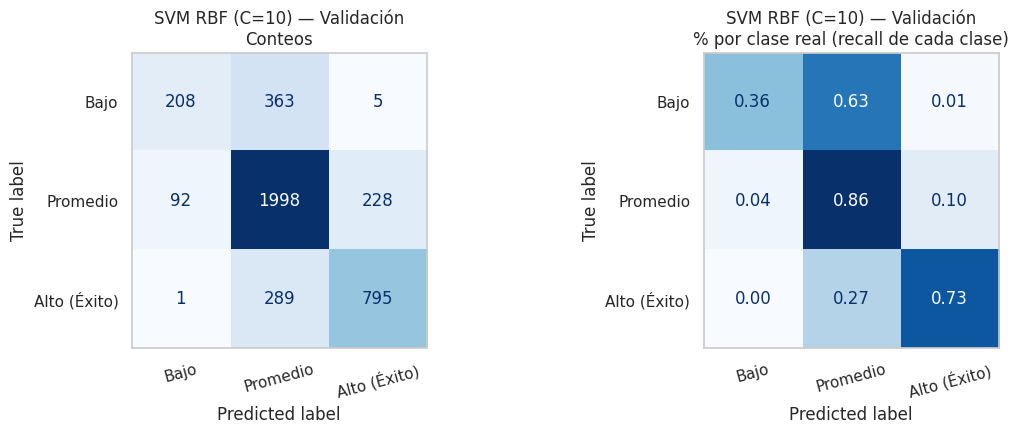

CV SVM | Accuracy: 0.753 (+/- 0.011)
CV SVM | F1: 0.679 (+/- 0.013)


In [ ]:
# --- CELDA 14: SVM final: matriz de confusión y CV ---
svm = construir(SVC(kernel='rbf', C=best_C, gamma='scale'), escalar=True)
fila, pred = entrenar_y_medir(svm, 'SVM')
modelos['SVM'], filas_val['SVM'], preds_val['SVM'] = svm, fila, pred
display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_cm(y_val, pred, f'SVM RBF (C={best_C}) — Validación')

correr_cv('SVM', construir(SVC(kernel='rbf', C=best_C, gamma='scale'), escalar=True))


## **5. Fronteras de decisión (visualización en 2 variables)**

Cada modelo traza fronteras distintas. Para poder dibujarlas se entrenan con **solo 2 variables** (`members` y `favorites`, en escala logarítmica) sobre una muestra de 2000 animes. Es una ilustración del *estilo* de cada modelo: la comparación real (con todas las variables) viene en la sección 7.

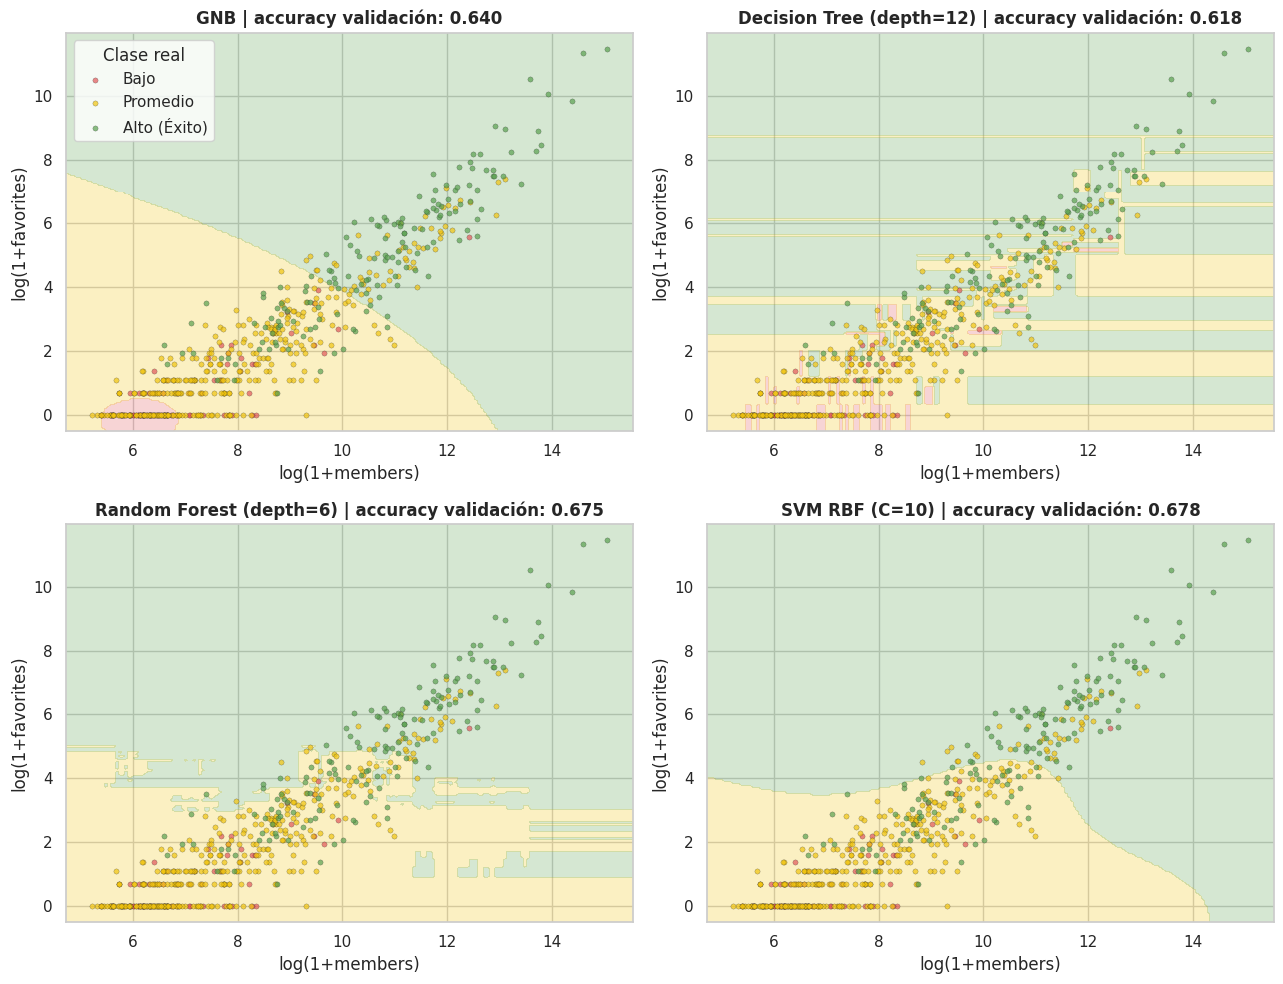

In [ ]:
# --- CELDA 15: Fronteras de decisión de los 4 modelos ---
from matplotlib.colors import ListedColormap

VAR_X, VAR_Y = 'members', 'favorites'          # puedes cambiarlas por otras dos numéricas
colores = ['#e15759', '#f1c40f', '#59a14f']     # Bajo, Promedio, Alto
cmap_fondo = ListedColormap(colores)

sub = df_clean[[VAR_X, VAR_Y, 'categoria_exito']].dropna()
sub = sub.sample(n=min(2000, len(sub)), random_state=SEED)
Xb = np.log1p(sub[[VAR_X, VAR_Y]].clip(lower=0)).values
yb = sub['categoria_exito'].map({c: i for i, c in enumerate(ORDEN_CLASES)}).values
Xb_tr, Xb_va, yb_tr, yb_va = train_test_split(Xb, yb, test_size=.30, stratify=yb, random_state=SEED)

modelos_2d = {
    'GNB': GaussianNB(),
    f'Decision Tree (depth={best_depth})': DecisionTreeClassifier(max_depth=best_depth, random_state=SEED),
    'Random Forest (depth=6)': RandomForestClassifier(n_estimators=best_n, max_depth=6, random_state=SEED, n_jobs=-1),
    f'SVM RBF (C={best_C})': make_pipeline(StandardScaler(), SVC(C=best_C, gamma='scale')),
}

pad = 0.5
x_min, x_max = Xb[:, 0].min() - pad, Xb[:, 0].max() + pad
y_min, y_max = Xb[:, 1].min() - pad, Xb[:, 1].max() + pad
g0, g1 = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
malla = np.column_stack([g0.ravel(), g1.ravel()])

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (nombre, m) in zip(axes.ravel(), modelos_2d.items()):
    m.fit(Xb_tr, yb_tr)
    Z = m.predict(malla).reshape(g0.shape)
    ax.contourf(g0, g1, Z, levels=[-.5, .5, 1.5, 2.5], cmap=cmap_fondo, alpha=.25)
    for k, nom in enumerate(ORDEN_CLASES):
        ax.scatter(Xb_va[yb_va == k, 0], Xb_va[yb_va == k, 1], s=14, color=colores[k], alpha=.7,
                   edgecolor='k', linewidth=.2, label=nom)
    ax.set_title(f'{nombre} | accuracy validación: {m.score(Xb_va, yb_va):.3f}', fontweight='bold')
    ax.set_xlabel(f'log(1+{VAR_X})'); ax.set_ylabel(f'log(1+{VAR_Y})')
axes[0, 0].legend(title='Clase real', loc='best')
plt.tight_layout(); plt.show()


## **6. Sobreajuste y subajuste**

Una gran diferencia entre el rendimiento en **train** y en **validación** indica sobreajuste; un rendimiento bajo en ambos sugiere subajuste. Primero se estudia cómo `gamma` (alcance de cada observación en el kernel RBF) lleva al SVM de un extremo al otro; después se resume la **brecha train–validación** de los 4 modelos finales.

,gamma,F1 train,F1 validación,Brecha (train - val)
0,0.001,0.481,0.467,0.013
1,0.010,0.504,0.487,0.017
2,0.100,0.644,0.614,0.030
3,1.000,0.776,0.641,0.135
4,10.000,0.885,0.465,0.420
5,100.000,0.948,0.353,0.595


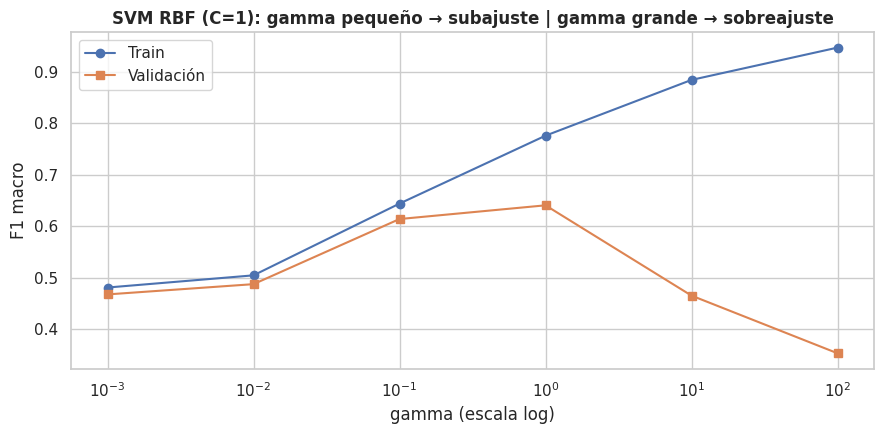

In [ ]:
# --- CELDA 16: SVM — efecto de gamma (subajuste -> sobreajuste) ---
# Para que sea rápido se entrena con una submuestra estratificada de train (máx. 4000 filas).
if len(X_train) > 4000:
    X_s, _, y_s, _ = train_test_split(X_train, y_train, train_size=4000, stratify=y_train, random_state=SEED)
else:
    X_s, y_s = X_train, y_train

gammas = [0.001, 0.01, 0.1, 1, 10, 100]
filas = []
for g in gammas:
    m = construir(SVC(kernel='rbf', C=1, gamma=g), escalar=True).fit(X_s, y_s)
    filas.append({'gamma': g,
                  'F1 train': f1_score(y_s, m.predict(X_s), average='macro', labels=ORDEN_CLASES, zero_division=0),
                  'F1 validación': f1_score(y_val, m.predict(X_val), average='macro', labels=ORDEN_CLASES, zero_division=0)})
df_gamma = pd.DataFrame(filas)
df_gamma['Brecha (train - val)'] = df_gamma['F1 train'] - df_gamma['F1 validación']
display(df_gamma.round(3))

plt.figure(figsize=(9, 4.5))
plt.semilogx(df_gamma['gamma'], df_gamma['F1 train'], 'o-', label='Train')
plt.semilogx(df_gamma['gamma'], df_gamma['F1 validación'], 's-', label='Validación')
plt.xlabel('gamma (escala log)'); plt.ylabel('F1 macro')
plt.title('SVM RBF (C=1): gamma pequeño → subajuste | gamma grande → sobreajuste', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()


,F1 train,F1 validación,Brecha
GNB,0.449,0.441,0.008
DT,0.781,0.635,0.146
RF,1.000,0.680,0.320
SVM,0.723,0.677,0.046


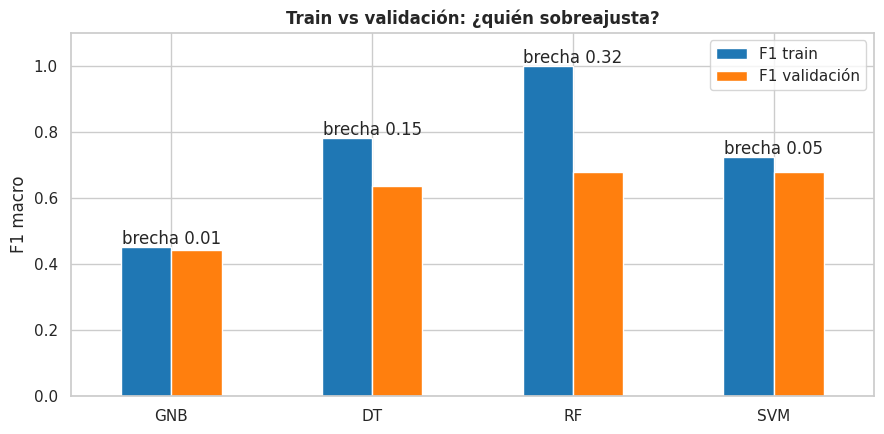

In [ ]:
# --- CELDA 17: Brecha train vs validación de los 4 modelos finales ---
nombres = ['GNB', 'DT', 'RF', 'SVM']
brecha = pd.DataFrame({'F1 train': [filas_val[n]['F1 train (macro)'] for n in nombres],
                       'F1 validación': [filas_val[n]['F1 (macro)'] for n in nombres]}, index=nombres)
brecha['Brecha'] = brecha['F1 train'] - brecha['F1 validación']
display(brecha.round(3))

ax = brecha[['F1 train', 'F1 validación']].plot(kind='bar', figsize=(9, 4.5), rot=0, color=['tab:blue', 'tab:orange'])
for i, n in enumerate(nombres):
    ax.text(i, max(brecha.loc[n, ['F1 train', 'F1 validación']]) + 0.01, f"brecha {brecha.loc[n, 'Brecha']:.2f}", ha='center')
ax.set_ylabel('F1 macro'); ax.set_ylim(0, 1.1)
ax.set_title('Train vs validación: ¿quién sobreajusta?', fontweight='bold')
plt.tight_layout(); plt.show()


## **7. Comparación final de los métodos**

Se comparan GNB, DT, RF y SVM (con los hiperparámetros elegidos en validación) sobre **el mismo conjunto de validación** y con **los mismos 5 folds de CV**. Criterio de selección: **F1 macro de validación** (en caso de empate se conserva el primero de la tabla: GNB, DT, RF, SVM).

=== TABLA COMPARATIVA (conjunto de validación) ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Brecha F1 (train-val),Tiempo entrenamiento (s)
Modelo,,,,,,
GNB,0.445,0.525,0.613,0.441,0.008,0.169
DT,0.706,0.661,0.621,0.635,0.146,0.259
RF,0.744,0.715,0.661,0.680,0.320,9.270
SVM,0.754,0.739,0.652,0.677,0.046,9.477


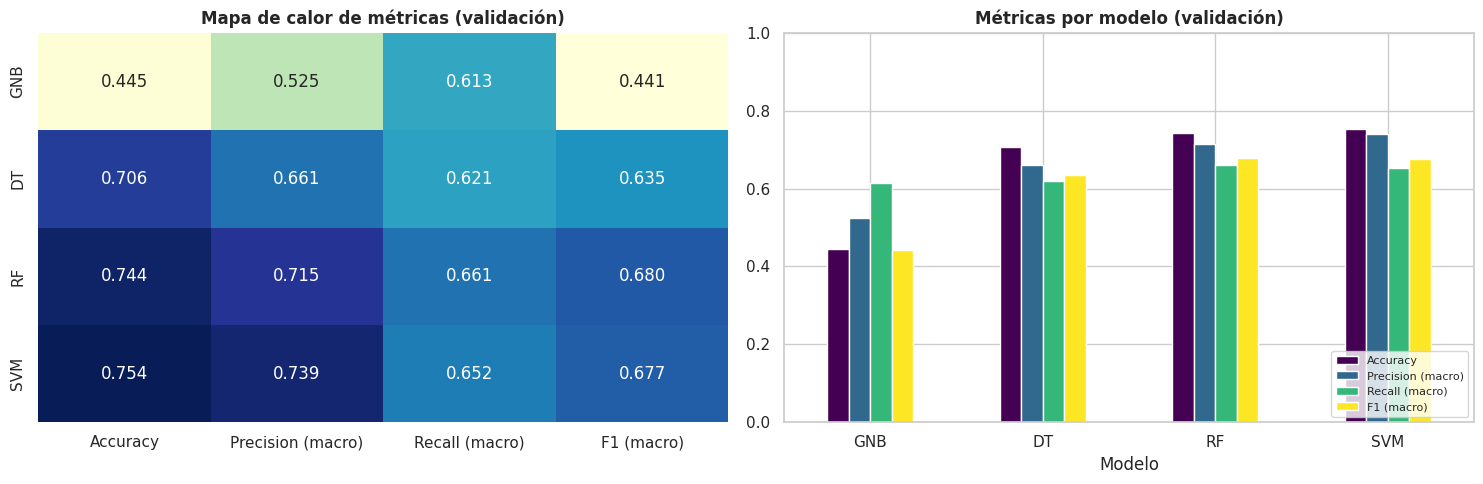

=== F1 POR CLASE (validación) ===


,GNB,DT,RF,SVM
Bajo,0.442,0.444,0.509,0.474
Promedio,0.270,0.763,0.792,0.804
Alto (Éxito),0.611,0.697,0.738,0.752


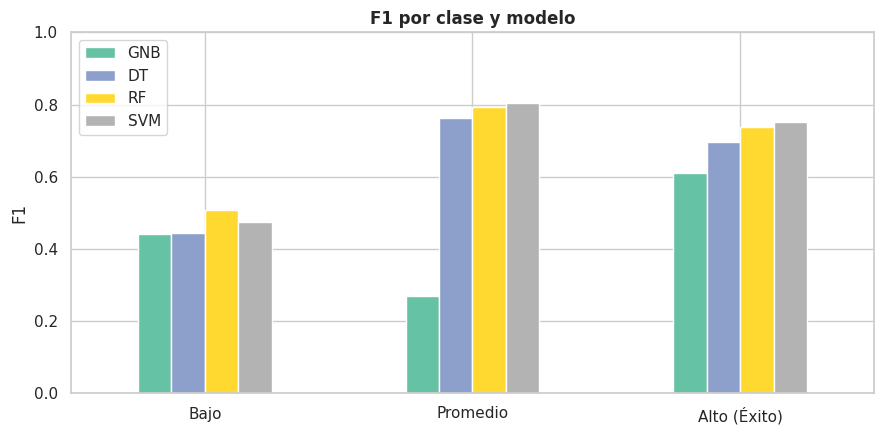

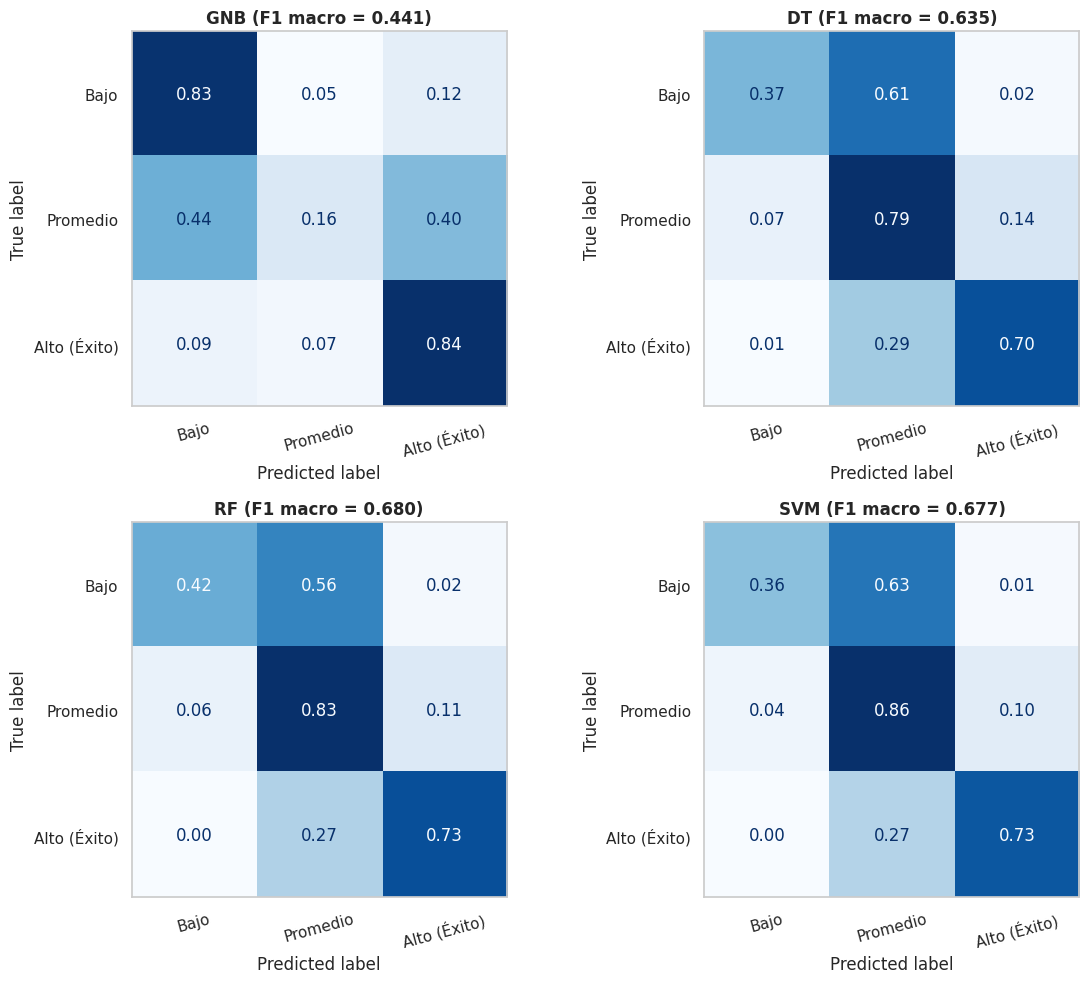

In [ ]:
# --- CELDA 18: Tabla comparativa y gráficas sobre validación ---
nombres = ['GNB', 'DT', 'RF', 'SVM']
tabla_val = pd.DataFrame([filas_val[n] for n in nombres]).set_index('Modelo')
tabla_val['Brecha F1 (train-val)'] = tabla_val['F1 train (macro)'] - tabla_val['F1 (macro)']
metricas = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']

print("=== TABLA COMPARATIVA (conjunto de validación) ===")
display(tabla_val[metricas + ['Brecha F1 (train-val)', 'Tiempo entrenamiento (s)']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(tabla_val[metricas], annot=True, fmt='.3f', cmap='YlGnBu', ax=axes[0], cbar=False)
axes[0].set_title('Mapa de calor de métricas (validación)', fontweight='bold'); axes[0].set_ylabel('')
tabla_val[metricas].plot(kind='bar', ax=axes[1], rot=0, colormap='viridis')
axes[1].set_ylim(0, 1); axes[1].set_title('Métricas por modelo (validación)', fontweight='bold')
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

# F1 por clase: ¿qué modelo falla en qué categoría?
f1_clase = pd.DataFrame({n: precision_recall_fscore_support(y_val, preds_val[n], labels=ORDEN_CLASES,
                                                            zero_division=0)[2] for n in nombres}, index=ORDEN_CLASES)
print("=== F1 POR CLASE (validación) ===")
display(f1_clase.round(3))
f1_clase.plot(kind='bar', figsize=(9, 4.5), rot=0, colormap='Set2')
plt.ylabel('F1'); plt.ylim(0, 1); plt.title('F1 por clase y modelo', fontweight='bold')
plt.tight_layout(); plt.show()

# Matrices de confusión normalizadas, lado a lado
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, n in zip(axes.ravel(), nombres):
    ConfusionMatrixDisplay.from_predictions(y_val, preds_val[n], labels=ORDEN_CLASES, normalize='true',
                                            values_format='.2f', cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f"{n} (F1 macro = {tabla_val.loc[n, 'F1 (macro)']:.3f})", fontweight='bold')
    ax.grid(False); ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()


=== VALIDACIÓN CRUZADA (5 folds sobre train) ===


,Accuracy medio,Accuracy std,F1 medio,F1 std
GNB,0.441,0.029,0.438,0.028
DT,0.702,0.011,0.628,0.016
RF,0.748,0.009,0.681,0.012
SVM,0.753,0.011,0.679,0.013


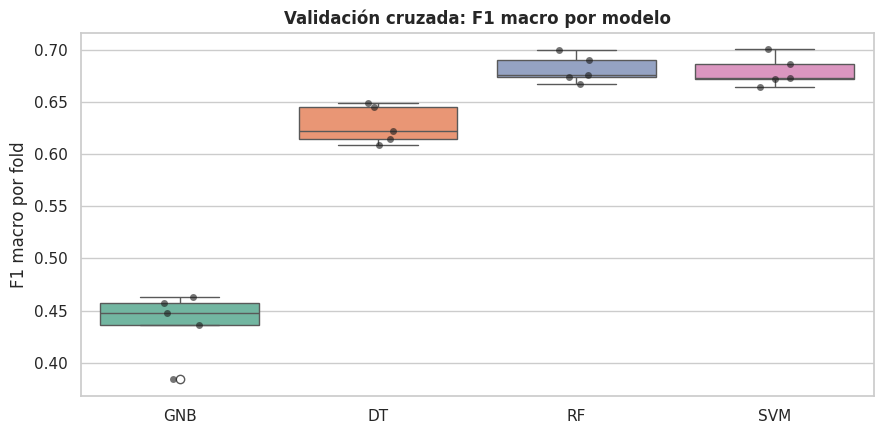

In [ ]:
# --- CELDA 19: Comparación con validación cruzada (estabilidad entre folds) ---
cv_tabla = pd.DataFrame({
    'Accuracy medio': [np.mean(cv_resultados[n]['test_Accuracy']) for n in nombres],
    'Accuracy std': [np.std(cv_resultados[n]['test_Accuracy']) for n in nombres],
    'F1 medio': [np.mean(cv_resultados[n]['test_F1']) for n in nombres],
    'F1 std': [np.std(cv_resultados[n]['test_F1']) for n in nombres]}, index=nombres)
print("=== VALIDACIÓN CRUZADA (5 folds sobre train) ===")
display(cv_tabla.round(3))

datos_box = pd.DataFrame({n: cv_resultados[n]['test_F1'] for n in nombres})
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=datos_box, palette='Set2')
sns.stripplot(data=datos_box, color='k', size=5, alpha=.6)
plt.ylabel('F1 macro por fold'); plt.title('Validación cruzada: F1 macro por modelo', fontweight='bold')
plt.tight_layout(); plt.show()


In [ ]:
# --- CELDA 20: Ranking y veredicto automático ---
ranking = tabla_val[metricas].rank(ascending=False, method='min')
ranking['F1 CV (medio)'] = cv_tabla['F1 medio'].rank(ascending=False, method='min')
ranking['Ranking promedio'] = ranking.mean(axis=1)
print("=== RANKING (1 = mejor) ===")
display(ranking.sort_values('Ranking promedio').round(2))

selected_name = tabla_val['F1 (macro)'].idxmax()            # en empate: el primero de la tabla
mejor_cv = cv_tabla['F1 medio'].idxmax()
orden = tabla_val['F1 (macro)'].sort_values(ascending=False)
segundo = orden.index[1]
dif = orden.iloc[0] - orden.iloc[1]
std_mejor = cv_tabla.loc[selected_name, 'F1 std']
peor_clase = f1_clase[selected_name].idxmin()

print("\n" + "=" * 70)
print("VEREDICTO")
print("=" * 70)
print(f"• Mejor modelo por F1 macro en validación: {selected_name} ({orden.iloc[0]:.3f}).")
print(f"• Mejor modelo por F1 macro medio en CV : {mejor_cv} ({cv_tabla.loc[mejor_cv, 'F1 medio']:.3f}).")
print("  → Ambos criterios " + ("coinciden." if selected_name == mejor_cv else "NO coinciden: la decisión es menos clara."))
print(f"• Ventaja sobre el segundo ({segundo}): {dif:.3f} de F1 "
      + ("(menor que la desviación entre folds de CV → diferencia poco concluyente; "
         "en la práctica podrían considerarse empatados y elegirse el más simple/rápido)."
         if dif < std_mejor else "(mayor que la desviación entre folds de CV → ventaja consistente)."))
print(f"• Brecha train-validación de {selected_name}: {tabla_val.loc[selected_name, 'Brecha F1 (train-val)']:.3f} "
      + ("→ señales de sobreajuste." if tabla_val.loc[selected_name, 'Brecha F1 (train-val)'] > 0.10 else "→ sin sobreajuste marcado."))
print(f"• Tiempo de entrenamiento de {selected_name}: {tabla_val.loc[selected_name, 'Tiempo entrenamiento (s)']:.1f} s.")
print(f"• Su clase más difícil es '{peor_clase}' (F1 = {f1_clase.loc[peor_clase, selected_name]:.3f}).")
print(f"\nModelo seleccionado: {selected_name}")


=== RANKING (1 = mejor) ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 CV (medio),Ranking promedio
Modelo,,,,,,
RF,2.0,2.0,1.0,1.0,1.0,1.4
SVM,1.0,1.0,2.0,2.0,2.0,1.6
DT,3.0,3.0,3.0,3.0,3.0,3.0
GNB,4.0,4.0,4.0,4.0,4.0,4.0



VEREDICTO
• Mejor modelo por F1 macro en validación: RF (0.680).
• Mejor modelo por F1 macro medio en CV : RF (0.681).
  → Ambos criterios coinciden.
• Ventaja sobre el segundo (SVM): 0.003 de F1 (menor que la desviación entre folds de CV → diferencia poco concluyente; en la práctica podrían considerarse empatados y elegirse el más simple/rápido).
• Brecha train-validación de RF: 0.320 → señales de sobreajuste.
• Tiempo de entrenamiento de RF: 9.3 s.
• Su clase más difícil es 'Bajo' (F1 = 0.509).

Modelo seleccionado: RF


=== RESULTADO FINAL EN TEST: RF ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Modelo,,,,
RF,0.756,0.733,0.674,0.694


              precision    recall  f1-score   support

        Bajo       0.67      0.44      0.53       576
    Promedio       0.77      0.84      0.80      2318
Alto (Éxito)       0.76      0.74      0.75      1085

    accuracy                           0.76      3979
   macro avg       0.73      0.67      0.69      3979
weighted avg       0.75      0.76      0.75      3979



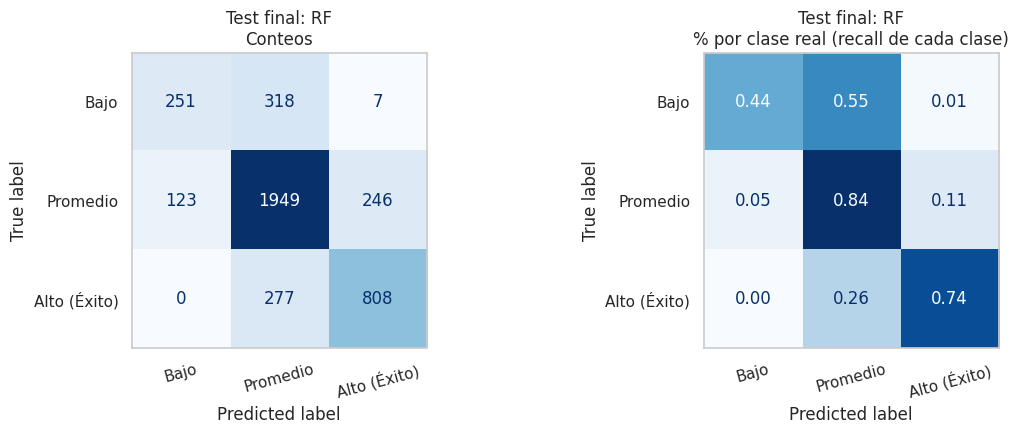

In [ ]:
# --- CELDA 21: Evaluación final en TEST (se ejecuta una sola vez, con la configuración ya fijada) ---
# Se reentrena el modelo elegido con train + validación (80% del total).
final_model = clone(modelos[selected_name])
final_model.fit(X_dev, y_dev)
y_test_pred = final_model.predict(X_test)

print(f"=== RESULTADO FINAL EN TEST: {selected_name} ===")
display(pd.DataFrame([metric_row(selected_name, y_test, y_test_pred)]).set_index('Modelo').round(3))
print(classification_report(y_test, y_test_pred, labels=ORDEN_CLASES, zero_division=0))
plot_cm(y_test, y_test_pred, f'Test final: {selected_name}')


## **Conclusiones**

*Escribe aquí tus conclusiones con base en las tablas y gráficas anteriores. Sugerencias de qué responder:*

1. ¿Qué modelo obtuvo el mejor F1 macro en validación y en CV? ¿Coinciden?
2. ¿La diferencia entre el primero y el segundo es mayor que la variación entre folds?
3. ¿Qué modelos sobreajustan (brecha train–validación) y cuáles subajustan?
4. ¿Qué clase es la más difícil de predecir y por qué (revisa cuál es la clase minoritaria en tu distribución)?
5. ¿Qué variables fueron las más importantes en DT y RF? ¿Tiene sentido para el negocio?
6. ¿El resultado en test confirma lo visto en validación?

---

# **Avance 3 — Modelos de regresión y comparación**

Se repiten los mismos cuatro modelos del Avance 2, pero ahora como **regresores** que predicen directamente el valor numérico de `score` (en lugar de la categoría `categoria_exito`):

| Clasificación | Regresión |
|---|---|
| Gaussian Naive Bayes (GNB) | **Bayesian Ridge** (punto de partida) |
| Decision Tree | **Decision Tree Regressor** |
| Random Forest | **Random Forest Regressor** |
| SVM (SVC) | **SVR** (Support Vector Regression) |

> ⚠️ **Nota sobre GNB:** Naive Bayes es, por definición, un clasificador y no existe una versión de regresión en scikit-learn. Se reemplaza por **Bayesian Ridge**, que cumple el mismo papel de *modelo probabilístico simple* usado como referencia (regresión lineal con distribuciones a priori sobre los coeficientes).

- Se usa **exactamente la misma partición** 60% train / 20% validación / 20% test (mismas filas que en clasificación), el mismo preprocesamiento y los mismos 5 folds de validación cruzada.
- Métricas: **MAE** (error medio en puntos de score), **RMSE** (penaliza más los errores grandes) y **R²** (proporción de varianza explicada; 0 = igual que predecir la media).
- Criterio de selección del mejor modelo: **RMSE en validación** (menor es mejor).
- Se incluye además un **modelo ingenuo** (predecir siempre la media de train) como piso de referencia: cualquier modelo útil debe superarlo.

**Celda 22: Variable objetivo numérica, partición (idéntica a la de clasificación) y línea base**

In [ ]:
# --- CELDA 22: Variable objetivo numérica y partición idéntica a la de clasificación ---
from sklearn.linear_model import BayesianRidge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Misma partición que en clasificación: se reutilizan los índices de X_train / X_val / X_test / X_dev,
# así cada anime cae en el mismo conjunto que antes y los resultados son comparables.
y_reg = df_clean['score'].astype(float)
y_train_r, y_val_r = y_reg.loc[X_train.index], y_reg.loc[X_val.index]
y_test_r, y_dev_r = y_reg.loc[X_test.index], y_reg.loc[X_dev.index]

print(f"Train: {len(y_train_r)} | Validación: {len(y_val_r)} | Test: {len(y_test_r)}")
display(pd.DataFrame({'Train': y_train_r.describe(), 'Validación': y_val_r.describe(),
                      'Test': y_test_r.describe()}).round(3))


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


# Línea base ingenuo: predecir siempre la media de train (R² ≈ 0 por construcción)
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train_r)
p_dummy = dummy.predict(X_val)
rmse_base, mae_base = rmse(y_val_r, p_dummy), mean_absolute_error(y_val_r, p_dummy)
print(f"\nLínea base (predecir la media = {y_train_r.mean():.2f}) en validación: "
      f"MAE = {mae_base:.3f} | RMSE = {rmse_base:.3f} | R² = {r2_score(y_val_r, p_dummy):.3f}")

Train: 11934 | Validación: 3979 | Test: 3979


,Train,Validación,Test
count,11934.000,3979.000,3979.000
mean,6.423,6.433,6.425
std,0.886,0.893,0.902
min,1.890,2.680,2.240
25%,5.800,5.810,5.790
50%,6.410,6.420,6.430
75%,7.070,7.060,7.070
max,9.080,9.110,9.270



Línea base (predecir la media = 6.42) en validación: MAE = 0.715 | RMSE = 0.893 | R² = -0.000


**Celda 23: Funciones auxiliares (métricas, tiempos, gráficos de predicción/residuos y validación cruzada)**

In [ ]:
# --- CELDA 23: Funciones auxiliares de regresión ---
modelos_r, filas_val_r, preds_val_r, cv_resultados_r = {}, {}, {}, {}


def metric_row_r(nombre, y_true, y_pred):
    return {'Modelo': nombre,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': rmse(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}


def entrenar_y_medir_r(modelo, nombre):
    """Entrena con train y mide en validación (y también en train, para detectar sobreajuste)."""
    t0 = time.time()
    modelo.fit(X_train, y_train_r)
    t_fit = time.time() - t0
    p_tr, p_val = modelo.predict(X_train), modelo.predict(X_val)
    fila = metric_row_r(nombre, y_val_r, p_val)
    fila['MAE train'] = mean_absolute_error(y_train_r, p_tr)
    fila['RMSE train'] = rmse(y_train_r, p_tr)
    fila['R2 train'] = r2_score(y_train_r, p_tr)
    fila['Tiempo entrenamiento (s)'] = t_fit
    return fila, p_val


def plot_pred_r(y_true, y_pred, titulo):
    """Izquierda: score real vs predicho (ideal = diagonal). Derecha: residuos vs predicho (ideal = nube centrada en 0)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    res = y_true - y_pred
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    axes[0].scatter(y_true, y_pred, s=8, alpha=.35, color='tab:blue')
    lim = [min(y_true.min(), y_pred.min()) - .1, max(y_true.max(), y_pred.max()) + .1]
    axes[0].plot(lim, lim, 'r--', label='Predicción perfecta')
    axes[0].set_xlim(lim); axes[0].set_ylim(lim)
    axes[0].set_xlabel('Score real'); axes[0].set_ylabel('Score predicho'); axes[0].legend()
    axes[0].set_title(f'{titulo}\nReal vs predicho', fontweight='bold')
    axes[1].scatter(y_pred, res, s=8, alpha=.35, color='tab:orange')
    axes[1].axhline(0, color='r', linestyle='--')
    axes[1].set_xlabel('Score predicho'); axes[1].set_ylabel('Residuo (real - predicho)')
    axes[1].set_title(f'{titulo}\nResiduos', fontweight='bold')
    plt.tight_layout(); plt.show()


# Mismos 5 folds que en clasificación (cv_splits), solo sobre train: así la comparación es justa.
scoring_cv_r = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}


def correr_cv_r(nombre, modelo):
    """Validación cruzada (mismos 5 folds para todos los modelos), solo sobre train."""
    s = cross_validate(modelo, X_train, y_train_r, cv=cv_splits, scoring=scoring_cv_r)
    s = {'test_MAE': -s['test_MAE'], 'test_RMSE': -s['test_RMSE'], 'test_R2': s['test_R2']}   # errores en positivo
    cv_resultados_r[nombre] = s
    for m in ['RMSE', 'R2']:
        v = s[f'test_{m}']
        print(f"CV {nombre} | {m}: {np.mean(v):.3f} (+/- {np.std(v):.3f})")

## **1. Bayesian Ridge — punto de partida (equivalente al GNB)**

Regresión lineal con regularización bayesiana: asume una relación **lineal** entre las variables (ya transformadas con `log1p` y estandarizadas) y el score. Es simple, rápido e interpretable; sirve de referencia para saber si los modelos no lineales justifican su costo.

,MAE,RMSE,R2,MAE train,RMSE train,R2 train,Tiempo entrenamiento (s)
Modelo,,,,,,,
BayesianRidge,0.432,0.571,0.592,0.425,0.558,0.604,0.182


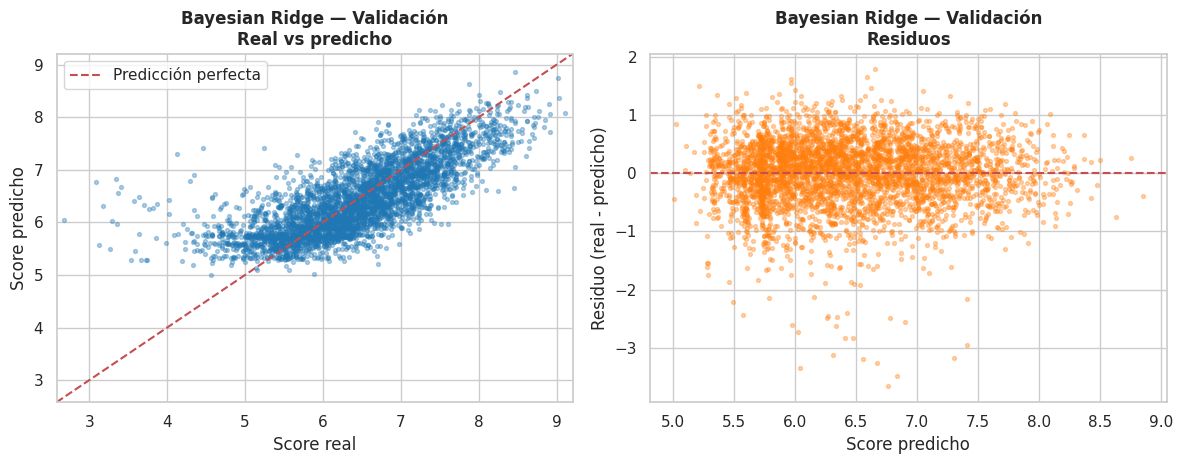

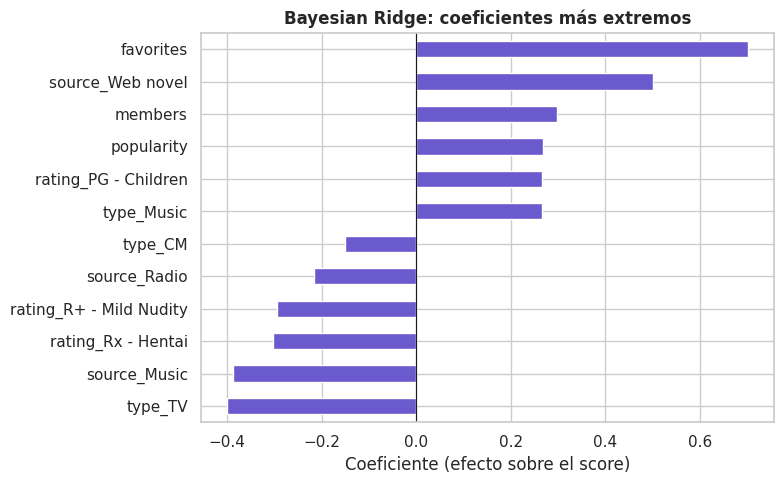

CV BayesianRidge | RMSE: 0.559 (+/- 0.012)
CV BayesianRidge | R2: 0.602 (+/- 0.012)


In [ ]:
# --- CELDA 24: Bayesian Ridge ---
br = construir(BayesianRidge(), escalar=True)
fila, pred = entrenar_y_medir_r(br, 'BayesianRidge')
modelos_r['BayesianRidge'], filas_val_r['BayesianRidge'], preds_val_r['BayesianRidge'] = br, fila, pred

display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_pred_r(y_val_r, pred, 'Bayesian Ridge — Validación')

# Coeficientes (sobre variables estandarizadas: su magnitud es comparable entre variables)
coef = pd.Series(br.named_steps['clf'].coef_, index=nombres_features(br)).sort_values()
plt.figure(figsize=(8, 5))
pd.concat([coef.head(6), coef.tail(6)]).drop_duplicates().plot(kind='barh', color='slateblue')
plt.axvline(0, color='k', lw=.8)
plt.title('Bayesian Ridge: coeficientes más extremos', fontweight='bold')
plt.xlabel('Coeficiente (efecto sobre el score)'); plt.tight_layout(); plt.show()

correr_cv_r('BayesianRidge', construir(BayesianRidge(), escalar=True))

## **2. Decision Tree Regressor**

El árbol divide el espacio con reglas `si variable ≤ umbral` y en cada hoja predice **el promedio del score** de los animes que cayeron ahí. `max_depth` controla su complejidad: poco profundo → **subajusta** (predice pocos valores distintos); muy profundo → memoriza el entrenamiento (**sobreajuste**). Se comparan **train vs. validación**.

,max_depth,RMSE train,RMSE val,R2 train,R2 val
0,1,0.703,0.727,0.371,0.337
1,2,0.646,0.666,0.469,0.444
2,3,0.616,0.635,0.517,0.495
3,4,0.597,0.621,0.547,0.516
4,6,0.557,0.591,0.605,0.562
5,8,0.516,0.574,0.660,0.588
6,12,0.422,0.588,0.774,0.567
7,None,0.000,0.715,1.000,0.359



Mejor profundidad según RMSE de validación: max_depth=8


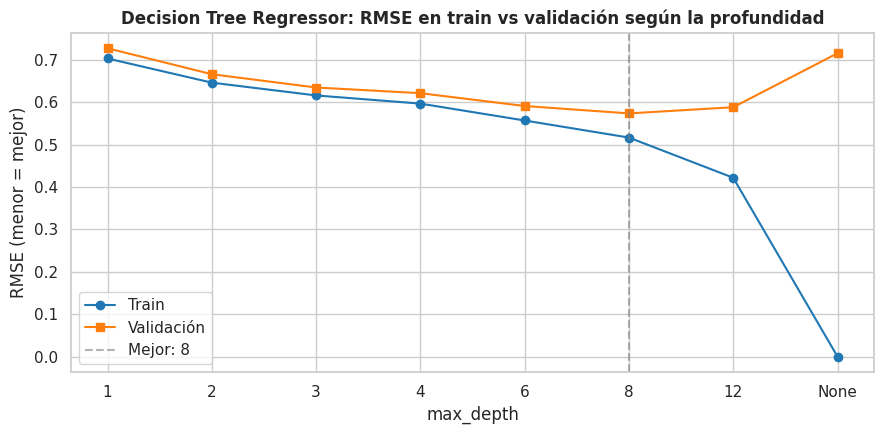

In [ ]:
# --- CELDA 25: Decision Tree Regressor — efecto de la profundidad (train vs validación) ---
profundidades_r = [1, 2, 3, 4, 6, 8, 12, None]
filas = []
for d in profundidades_r:
    f, _ = entrenar_y_medir_r(construir(DecisionTreeRegressor(max_depth=d, random_state=SEED)), 'DT')
    f['max_depth'] = str(d)
    filas.append(f)
df_depth_r = pd.DataFrame(filas)
display(df_depth_r[['max_depth', 'RMSE train', 'RMSE', 'R2 train', 'R2']]
        .rename(columns={'RMSE': 'RMSE val', 'R2': 'R2 val'}).round(3))

pos = int(np.argmin(df_depth_r['RMSE'].values))      # en empate gana la más simple (menor profundidad)
best_depth_r = profundidades_r[pos]
print(f"\nMejor profundidad según RMSE de validación: max_depth={best_depth_r}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df_depth_r['max_depth'], df_depth_r['RMSE train'], 'o-', label='Train', color='tab:blue')
ax.plot(df_depth_r['max_depth'], df_depth_r['RMSE'], 's-', label='Validación', color='tab:orange')
ax.axvline(pos, color='gray', linestyle='--', alpha=.6, label=f'Mejor: {best_depth_r}')
ax.set_xlabel('max_depth'); ax.set_ylabel('RMSE (menor = mejor)')
ax.set_title('Decision Tree Regressor: RMSE en train vs validación según la profundidad', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

,MAE,RMSE,R2,MAE train,RMSE train,R2 train,Tiempo entrenamiento (s)
Modelo,,,,,,,
DT,0.428,0.574,0.588,0.387,0.516,0.66,0.216


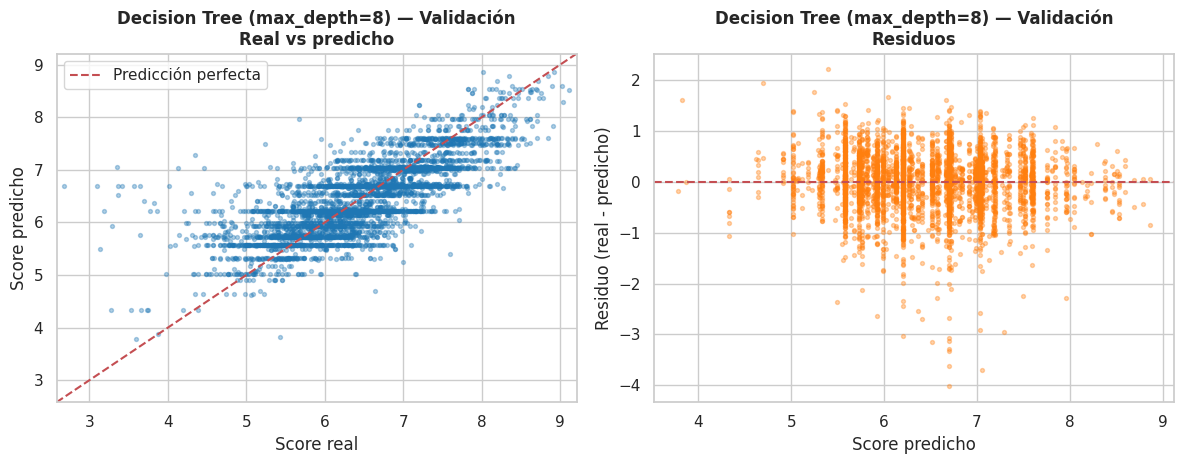

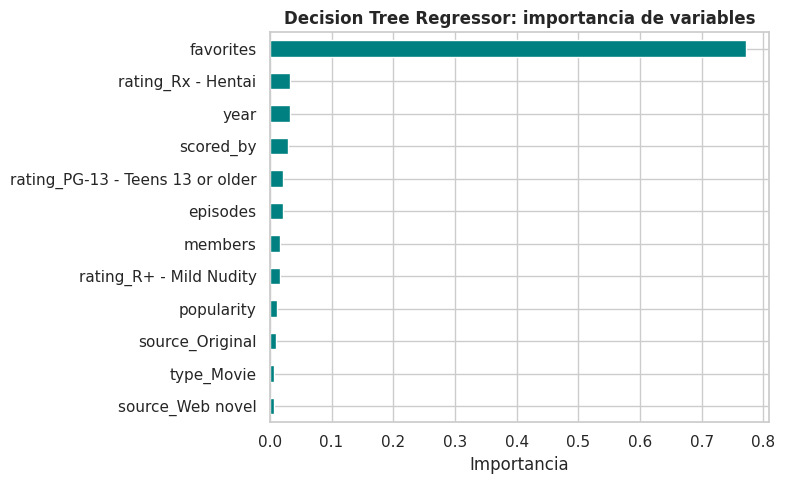

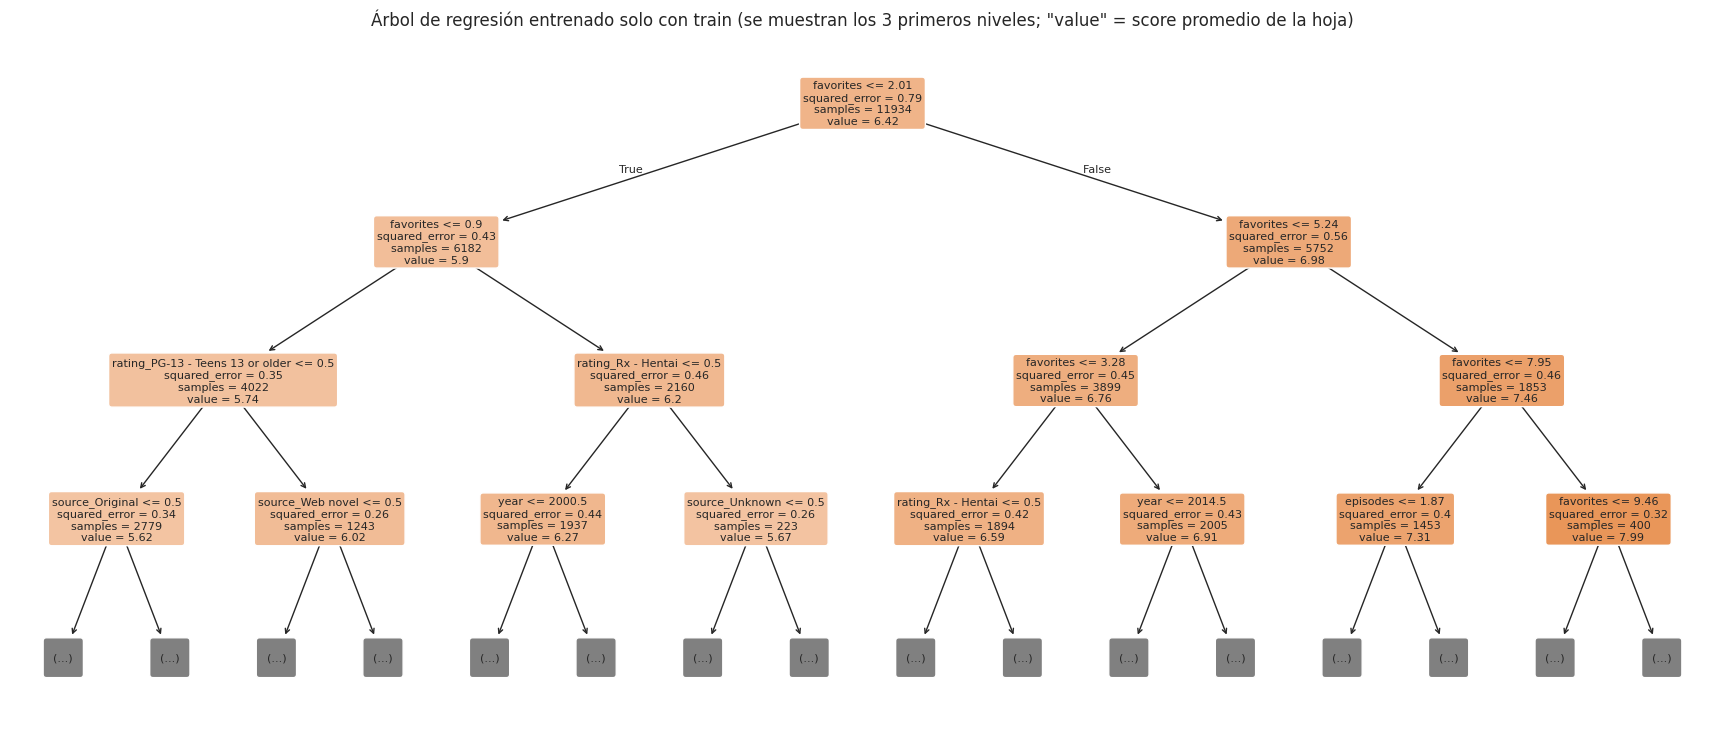

CV DT | RMSE: 0.570 (+/- 0.014)
CV DT | R2: 0.586 (+/- 0.016)


In [ ]:
# --- CELDA 26: Decision Tree Regressor final: predicción vs real, importancias, árbol y CV ---
dt_r = construir(DecisionTreeRegressor(max_depth=best_depth_r, random_state=SEED))
fila, pred = entrenar_y_medir_r(dt_r, 'DT')
modelos_r['DT'], filas_val_r['DT'], preds_val_r['DT'] = dt_r, fila, pred
display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_pred_r(y_val_r, pred, f'Decision Tree (max_depth={best_depth_r}) — Validación')

imp = pd.Series(dt_r.named_steps['clf'].feature_importances_, index=nombres_features(dt_r)).sort_values()
plt.figure(figsize=(8, 5))
imp.tail(12).plot(kind='barh', color='teal')
plt.title('Decision Tree Regressor: importancia de variables', fontweight='bold')
plt.xlabel('Importancia'); plt.tight_layout(); plt.show()

plt.figure(figsize=(22, 9))
plot_tree(dt_r.named_steps['clf'], max_depth=3, feature_names=nombres_features(dt_r),
          filled=True, rounded=True, fontsize=8, precision=2)
plt.title('Árbol de regresión entrenado solo con train (se muestran los 3 primeros niveles; "value" = score promedio de la hoja)')
plt.show()

correr_cv_r('DT', construir(DecisionTreeRegressor(max_depth=best_depth_r, random_state=SEED)))

## **3. Random Forest Regressor**

Promedia las predicciones de muchos árboles entrenados con muestras bootstrap y subconjuntos aleatorios de variables, lo que reduce la varianza de un árbol individual. Se explora `n_estimators` midiendo también el **tiempo de entrenamiento**.

,n_estimators,RMSE train,RMSE val,R2 val,Tiempo entrenamiento (s)
0,10,0.227,0.556,0.612,1.176
1,50,0.198,0.533,0.644,5.101
2,100,0.195,0.531,0.646,11.074
3,200,0.192,0.529,0.650,21.607



Mejor n_estimators según RMSE de validación: 200


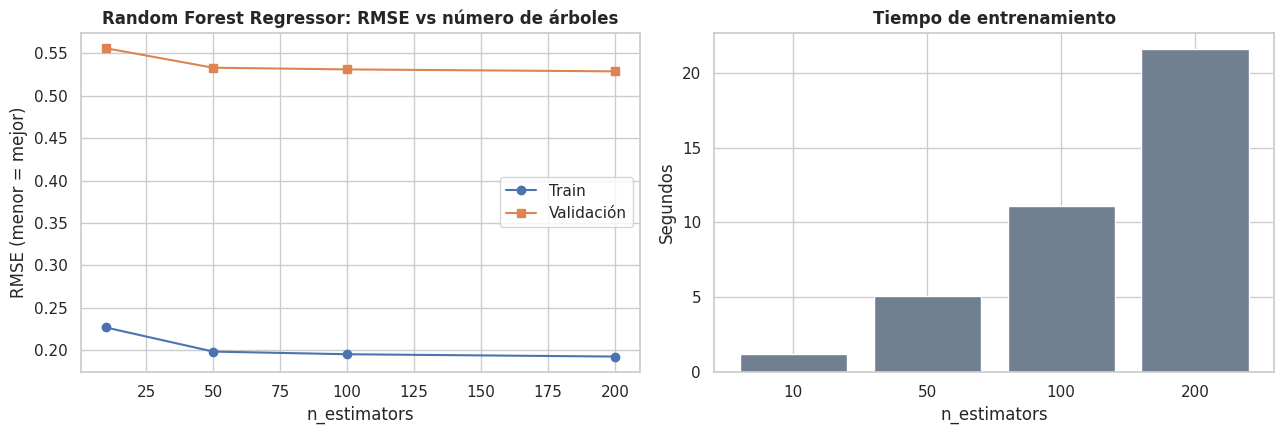

In [ ]:
# --- CELDA 27: Random Forest Regressor — efecto de n_estimators (rendimiento y tiempo) ---
n_trees_r = [10, 50, 100, 200]
filas = []
for n in n_trees_r:
    f, _ = entrenar_y_medir_r(construir(RandomForestRegressor(n_estimators=n, random_state=SEED, n_jobs=-1)), 'RF')
    f['n_estimators'] = n
    filas.append(f)
df_rf_r = pd.DataFrame(filas)
display(df_rf_r[['n_estimators', 'RMSE train', 'RMSE', 'R2', 'Tiempo entrenamiento (s)']]
        .rename(columns={'RMSE': 'RMSE val', 'R2': 'R2 val'}).round(3))

pos = int(np.argmin(df_rf_r['RMSE'].values))          # en empate gana el bosque más pequeño
best_n_r = n_trees_r[pos]
print(f"\nMejor n_estimators según RMSE de validación: {best_n_r}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df_rf_r['n_estimators'], df_rf_r['RMSE train'], 'o-', label='Train')
axes[0].plot(df_rf_r['n_estimators'], df_rf_r['RMSE'], 's-', label='Validación')
axes[0].set_xlabel('n_estimators'); axes[0].set_ylabel('RMSE (menor = mejor)'); axes[0].legend()
axes[0].set_title('Random Forest Regressor: RMSE vs número de árboles', fontweight='bold')
axes[1].bar(df_rf_r['n_estimators'].astype(str), df_rf_r['Tiempo entrenamiento (s)'], color='slategray')
axes[1].set_xlabel('n_estimators'); axes[1].set_ylabel('Segundos')
axes[1].set_title('Tiempo de entrenamiento', fontweight='bold')
plt.tight_layout(); plt.show()

,MAE,RMSE,R2,MAE train,RMSE train,R2 train,Tiempo entrenamiento (s)
Modelo,,,,,,,
RF,0.387,0.529,0.65,0.141,0.192,0.953,19.784


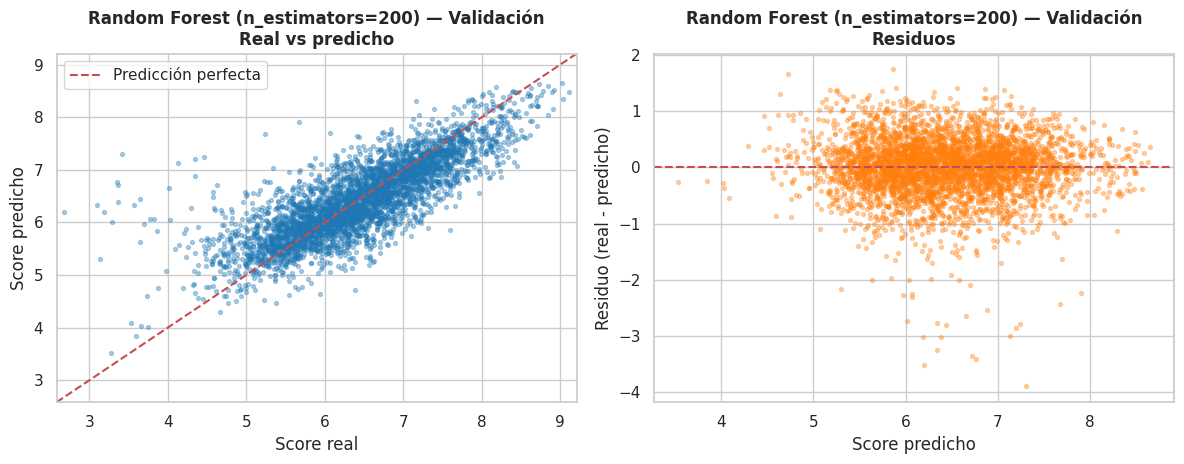

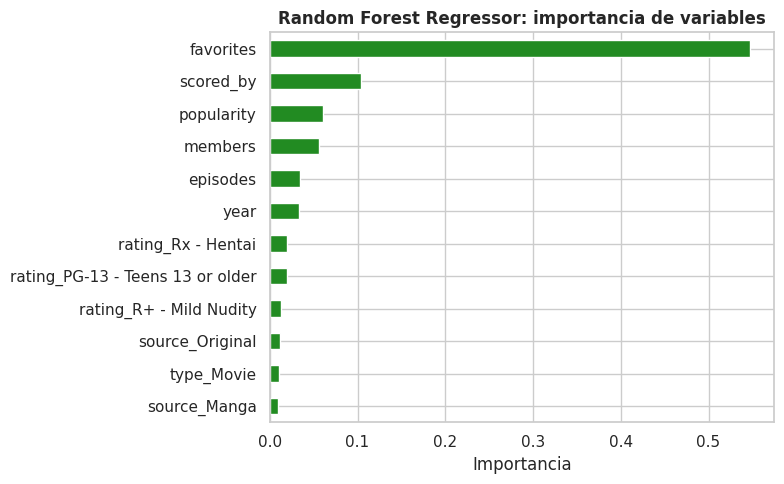

CV RF | RMSE: 0.520 (+/- 0.011)
CV RF | R2: 0.656 (+/- 0.010)


In [ ]:
# --- CELDA 28: Random Forest Regressor final: predicción vs real, importancias y CV ---
rf_r = construir(RandomForestRegressor(n_estimators=best_n_r, random_state=SEED, n_jobs=-1))
fila, pred = entrenar_y_medir_r(rf_r, 'RF')
modelos_r['RF'], filas_val_r['RF'], preds_val_r['RF'] = rf_r, fila, pred
display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_pred_r(y_val_r, pred, f'Random Forest (n_estimators={best_n_r}) — Validación')

imp = pd.Series(rf_r.named_steps['clf'].feature_importances_, index=nombres_features(rf_r)).sort_values()
plt.figure(figsize=(8, 5))
imp.tail(12).plot(kind='barh', color='forestgreen')
plt.title('Random Forest Regressor: importancia de variables', fontweight='bold')
plt.xlabel('Importancia'); plt.tight_layout(); plt.show()

correr_cv_r('RF', construir(RandomForestRegressor(n_estimators=best_n_r, random_state=SEED, n_jobs=-1)))

## **4. Support Vector Regression (SVR)**

Ajusta una función que **tolera errores de hasta `epsilon`** (tubo ε) y penaliza los que quedan fuera, controlando la complejidad con `C`. Con kernel RBF modela relaciones no lineales. Igual que SVM, es **sensible a la escala**, por eso se usa un `Pipeline` con `StandardScaler`. Se compara con y sin escalado y se prueban distintos valores de `C`.

> ⏱️ SVR es el modelo más lento de esta sección; con muchos datos puede tardar unos minutos.

,Configuración,RMSE train,RMSE val,R2 val,Tiempo entrenamiento (s)
0,Sin escalado,0.457,0.511,0.672,12.092
1,Con StandardScaler,0.485,0.517,0.665,10.879


,C,RMSE train,RMSE val,R2 val,Tiempo entrenamiento (s)
0,0.1,0.518,0.539,0.636,12.128
1,1.0,0.484,0.516,0.666,13.478
2,10.0,0.450,0.515,0.668,22.253



Mejor C según RMSE de validación: C=10


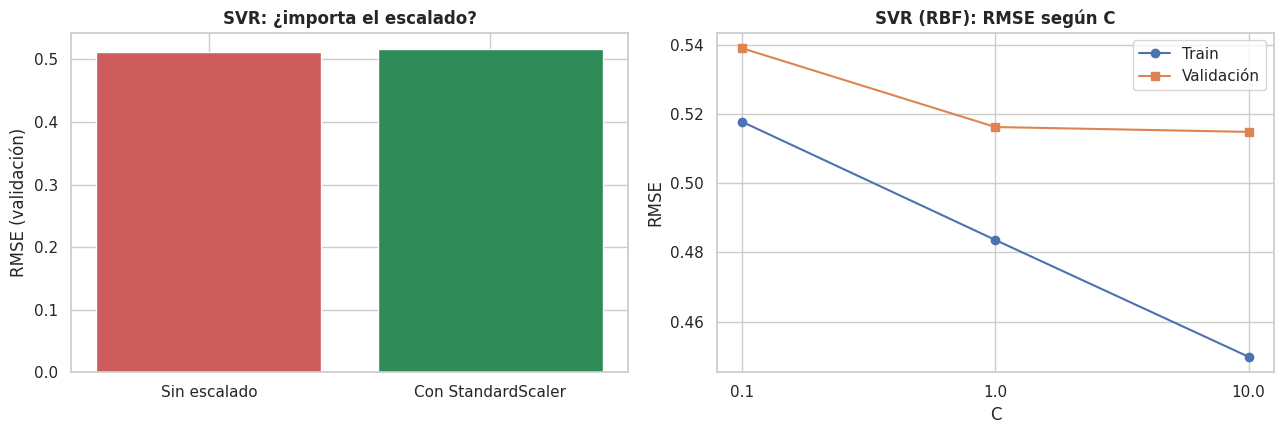

In [ ]:
# --- CELDA 29: SVR — con vs sin escalado, y efecto de C ---
# a) Con y sin StandardScaler (gamma fija = 0.1 en ambos, para que la comparación sea justa)
filas = []
for escalar in [False, True]:
    f, _ = entrenar_y_medir_r(construir(SVR(kernel='rbf', C=1, gamma=0.1), escalar=escalar), 'SVR')
    f['Configuración'] = 'Con StandardScaler' if escalar else 'Sin escalado'
    filas.append(f)
df_scale_r = pd.DataFrame(filas)
display(df_scale_r[['Configuración', 'RMSE train', 'RMSE', 'R2', 'Tiempo entrenamiento (s)']]
        .rename(columns={'RMSE': 'RMSE val', 'R2': 'R2 val'}).round(3))

# b) Efecto de C (con escalado, gamma='scale')
C_values_r = [0.1, 1, 10]
filas = []
for C in C_values_r:
    f, _ = entrenar_y_medir_r(construir(SVR(kernel='rbf', C=C, gamma='scale'), escalar=True), 'SVR')
    f['C'] = C
    filas.append(f)
df_C_r = pd.DataFrame(filas)
display(df_C_r[['C', 'RMSE train', 'RMSE', 'R2', 'Tiempo entrenamiento (s)']]
        .rename(columns={'RMSE': 'RMSE val', 'R2': 'R2 val'}).round(3))

pos = int(np.argmin(df_C_r['RMSE'].values))
best_C_r = C_values_r[pos]
print(f"\nMejor C según RMSE de validación: C={best_C_r}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(df_scale_r['Configuración'], df_scale_r['RMSE'], color=['indianred', 'seagreen'])
axes[0].set_ylabel('RMSE (validación)'); axes[0].set_title('SVR: ¿importa el escalado?', fontweight='bold')
axes[1].plot(df_C_r['C'].astype(str), df_C_r['RMSE train'], 'o-', label='Train')
axes[1].plot(df_C_r['C'].astype(str), df_C_r['RMSE'], 's-', label='Validación')
axes[1].set_xlabel('C'); axes[1].set_ylabel('RMSE'); axes[1].legend()
axes[1].set_title('SVR (RBF): RMSE según C', fontweight='bold')
plt.tight_layout(); plt.show()

,MAE,RMSE,R2,MAE train,RMSE train,R2 train,Tiempo entrenamiento (s)
Modelo,,,,,,,
SVR,0.375,0.515,0.668,0.312,0.45,0.742,20.012


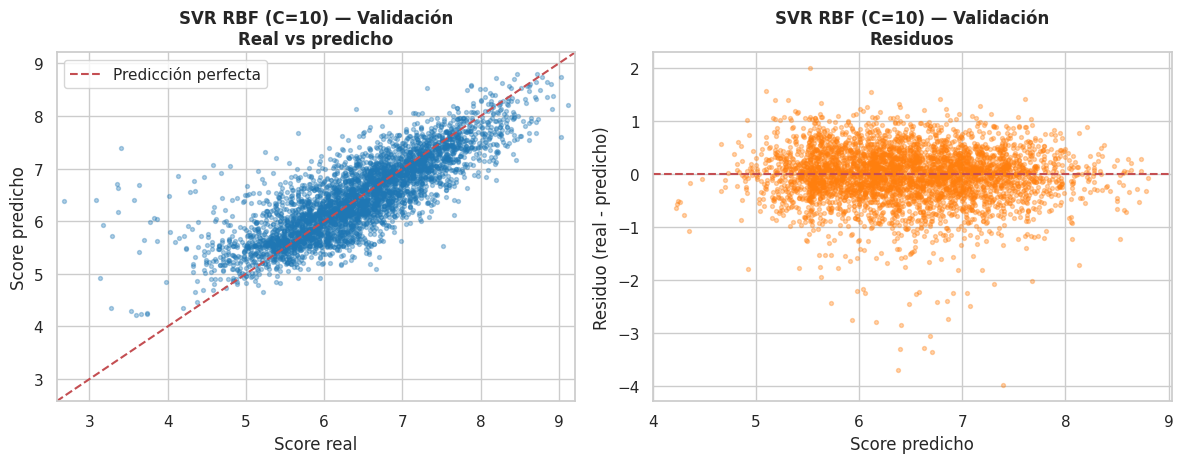

CV SVR | RMSE: 0.505 (+/- 0.014)
CV SVR | R2: 0.675 (+/- 0.014)


In [ ]:
# --- CELDA 30: SVR final: predicción vs real y CV ---
svr = construir(SVR(kernel='rbf', C=best_C_r, gamma='scale'), escalar=True)
fila, pred = entrenar_y_medir_r(svr, 'SVR')
modelos_r['SVR'], filas_val_r['SVR'], preds_val_r['SVR'] = svr, fila, pred
display(pd.DataFrame([fila]).set_index('Modelo').round(3))
plot_pred_r(y_val_r, pred, f'SVR RBF (C={best_C_r}) — Validación')

correr_cv_r('SVR', construir(SVR(kernel='rbf', C=best_C_r, gamma='scale'), escalar=True))

## **5. Superficie de predicción (visualización en 2 variables)**

En clasificación se dibujaban *fronteras* entre clases; en regresión cada modelo dibuja una **superficie de score predicho**. Se entrenan con **solo 2 variables** (`members` y `favorites`, en escala logarítmica) sobre una muestra de 2000 animes. El fondo es el score que predice el modelo y los puntos son animes de validación coloreados con su score real: cuanto más se parezca el color del punto al del fondo, mejor la predicción.

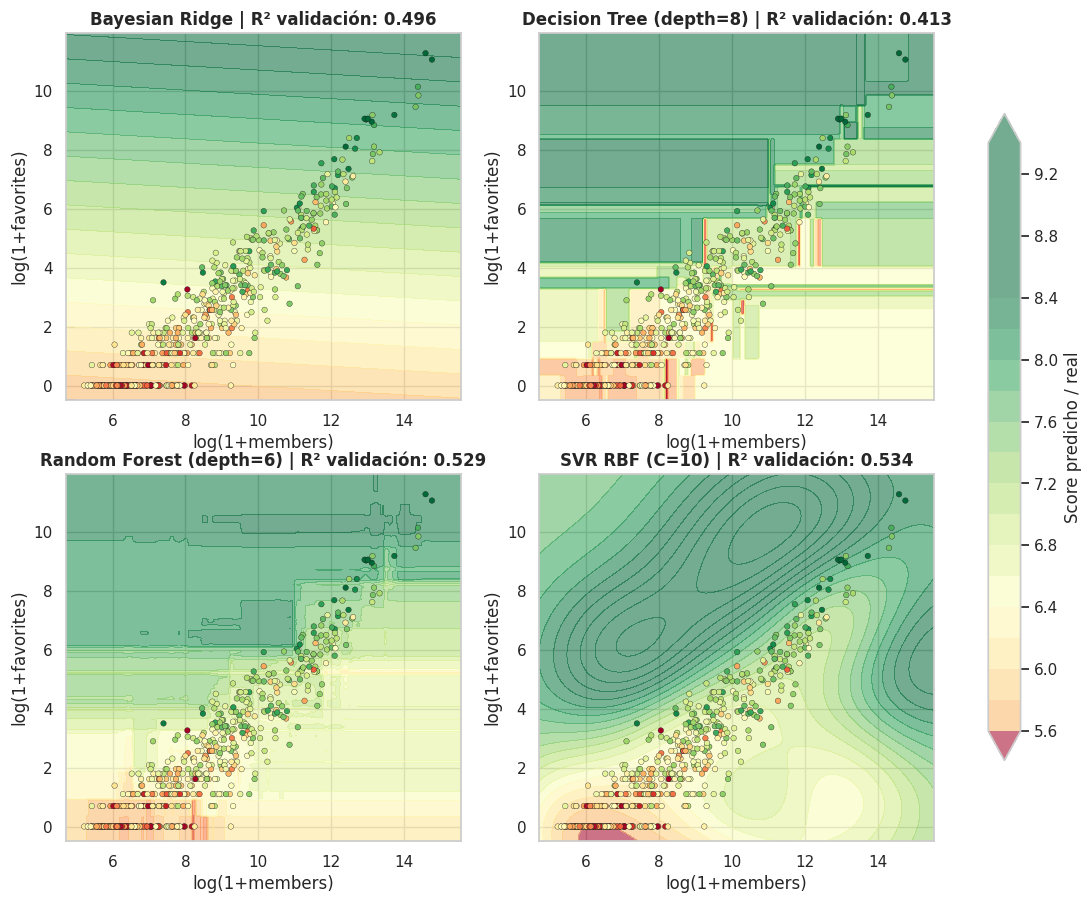

In [ ]:
# --- CELDA 31: Superficies de predicción de los 4 regresores ---
VAR_X_r, VAR_Y_r = 'members', 'favorites'

sub = df_clean[[VAR_X_r, VAR_Y_r, 'score']].dropna()
sub = sub.sample(n=min(2000, len(sub)), random_state=SEED)
Xb = np.log1p(sub[[VAR_X_r, VAR_Y_r]].clip(lower=0)).values
yb = sub['score'].values
Xb_tr, Xb_va, yb_tr, yb_va = train_test_split(Xb, yb, test_size=.30, random_state=SEED)

modelos_2d_r = {
    'Bayesian Ridge': make_pipeline(StandardScaler(), BayesianRidge()),
    f'Decision Tree (depth={best_depth_r})': DecisionTreeRegressor(max_depth=best_depth_r, random_state=SEED),
    'Random Forest (depth=6)': RandomForestRegressor(n_estimators=best_n_r, max_depth=6, random_state=SEED, n_jobs=-1),
    f'SVR RBF (C={best_C_r})': make_pipeline(StandardScaler(), SVR(C=best_C_r, gamma='scale')),
}

pad = 0.5
x_min, x_max = Xb[:, 0].min() - pad, Xb[:, 0].max() + pad
y_min, y_max = Xb[:, 1].min() - pad, Xb[:, 1].max() + pad
g0, g1 = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
malla = np.column_stack([g0.ravel(), g1.ravel()])
vmin, vmax = np.percentile(yb, 1), np.percentile(yb, 99)     # misma escala de color en los 4 paneles

fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))
for ax, (nombre, m) in zip(axes.ravel(), modelos_2d_r.items()):
    m.fit(Xb_tr, yb_tr)
    Z = m.predict(malla).reshape(g0.shape)
    cf = ax.contourf(g0, g1, Z, levels=20, cmap='RdYlGn', vmin=vmin, vmax=vmax, alpha=.55, extend='both')
    ax.scatter(Xb_va[:, 0], Xb_va[:, 1], c=yb_va, cmap='RdYlGn', vmin=vmin, vmax=vmax, s=16,
               edgecolor='k', linewidth=.25)
    ax.set_title(f'{nombre} | R² validación: {r2_score(yb_va, m.predict(Xb_va)):.3f}', fontweight='bold')
    ax.set_xlabel(f'log(1+{VAR_X_r})'); ax.set_ylabel(f'log(1+{VAR_Y_r})')
fig.colorbar(cf, ax=axes.ravel().tolist(), label='Score predicho / real', shrink=.8)
plt.show()

## **6. Sobreajuste y subajuste**

Una gran diferencia entre el error en **train** y en **validación** indica sobreajuste; un error alto en ambos sugiere subajuste. Primero se estudia cómo `gamma` lleva al SVR de un extremo al otro; después se resume la **brecha train–validación** de los 4 modelos finales.

,gamma,RMSE train,RMSE validación,Brecha (val - train)
0,0.001,0.579,0.603,0.023
1,0.010,0.540,0.563,0.023
2,0.100,0.483,0.532,0.048
3,1.000,0.377,0.585,0.208
4,10.000,0.318,0.731,0.413
5,100.000,0.304,0.817,0.513


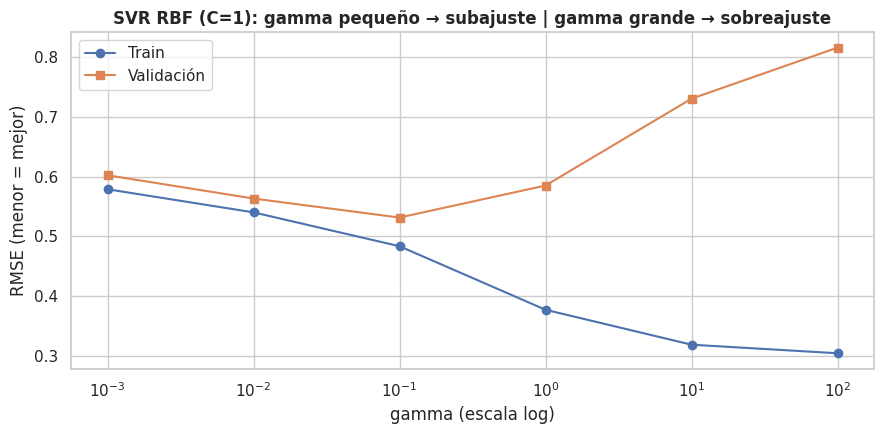

In [ ]:
# --- CELDA 32: SVR — efecto de gamma (subajuste -> sobreajuste) ---
# Para que sea rápido se entrena con una submuestra estratificada de train (máx. 4000 filas).
if len(X_train) > 4000:
    X_s, _, y_s, _ = train_test_split(X_train, y_train_r, train_size=4000, stratify=y_train, random_state=SEED)
else:
    X_s, y_s = X_train, y_train_r

gammas_r = [0.001, 0.01, 0.1, 1, 10, 100]
filas = []
for g in gammas_r:
    m = construir(SVR(kernel='rbf', C=1, gamma=g), escalar=True).fit(X_s, y_s)
    filas.append({'gamma': g,
                  'RMSE train': rmse(y_s, m.predict(X_s)),
                  'RMSE validación': rmse(y_val_r, m.predict(X_val))})
df_gamma_r = pd.DataFrame(filas)
df_gamma_r['Brecha (val - train)'] = df_gamma_r['RMSE validación'] - df_gamma_r['RMSE train']
display(df_gamma_r.round(3))

plt.figure(figsize=(9, 4.5))
plt.semilogx(df_gamma_r['gamma'], df_gamma_r['RMSE train'], 'o-', label='Train')
plt.semilogx(df_gamma_r['gamma'], df_gamma_r['RMSE validación'], 's-', label='Validación')
plt.xlabel('gamma (escala log)'); plt.ylabel('RMSE (menor = mejor)')
plt.title('SVR RBF (C=1): gamma pequeño → subajuste | gamma grande → sobreajuste', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

,RMSE train,RMSE validación,R2 train,R2 validación,Brecha RMSE (val-train),Brecha R2 (train-val)
BayesianRidge,0.558,0.571,0.604,0.592,0.013,0.012
DT,0.516,0.574,0.660,0.588,0.057,0.073
RF,0.192,0.529,0.953,0.650,0.337,0.303
SVR,0.450,0.515,0.742,0.668,0.065,0.075


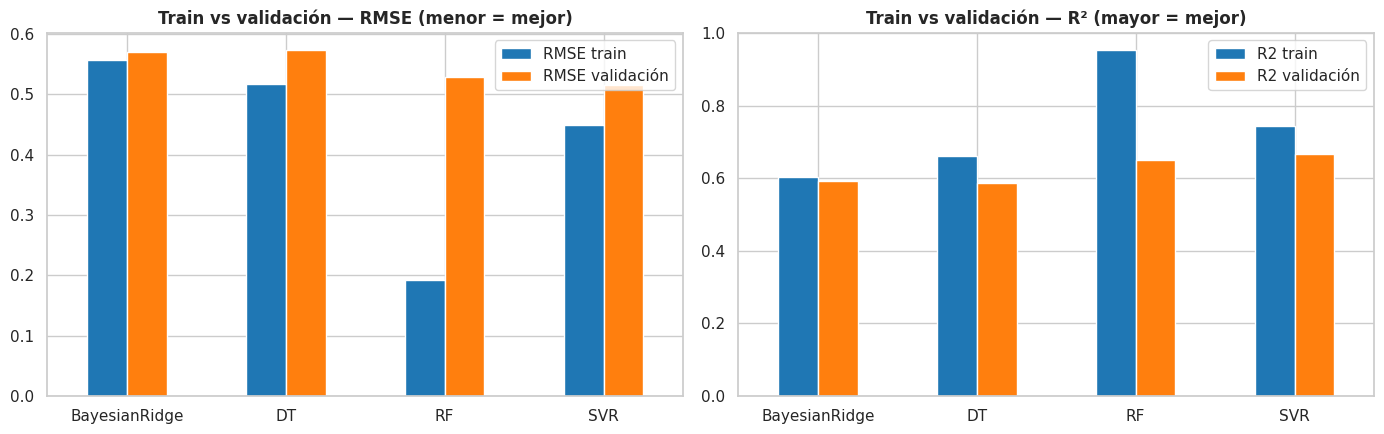

In [ ]:
# --- CELDA 33: Brecha train vs validación de los 4 modelos finales ---
nombres_r = ['BayesianRidge', 'DT', 'RF', 'SVR']
brecha_r = pd.DataFrame({'RMSE train': [filas_val_r[n]['RMSE train'] for n in nombres_r],
                         'RMSE validación': [filas_val_r[n]['RMSE'] for n in nombres_r],
                         'R2 train': [filas_val_r[n]['R2 train'] for n in nombres_r],
                         'R2 validación': [filas_val_r[n]['R2'] for n in nombres_r]}, index=nombres_r)
brecha_r['Brecha RMSE (val-train)'] = brecha_r['RMSE validación'] - brecha_r['RMSE train']
brecha_r['Brecha R2 (train-val)'] = brecha_r['R2 train'] - brecha_r['R2 validación']
display(brecha_r.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (a, b, tit) in zip(axes, [('RMSE train', 'RMSE validación', 'RMSE (menor = mejor)'),
                                  ('R2 train', 'R2 validación', 'R² (mayor = mejor)')]):
    brecha_r[[a, b]].plot(kind='bar', ax=ax, rot=0, color=['tab:blue', 'tab:orange'])
    ax.set_title(f'Train vs validación — {tit}', fontweight='bold')
plt.tight_layout(); plt.show()

## **7. Comparación final de los métodos**

Se comparan Bayesian Ridge, DT, RF y SVR (con los hiperparámetros elegidos en validación) sobre **el mismo conjunto de validación** y con **los mismos 5 folds de CV**. Criterio de selección: **RMSE de validación** (en caso de empate se conserva el primero de la tabla). Como complemento, las predicciones numéricas se **convierten de nuevo a las 3 categorías** (`Bajo` / `Promedio` / `Alto (Éxito)`) para poder compararlas directamente con los clasificadores del Avance 2.

=== TABLA COMPARATIVA (conjunto de validación) ===
(Referencia — modelo ingenuo que predice la media: MAE=0.715 | RMSE=0.893 | R²≈0)


,MAE,RMSE,R2,Brecha R2 (train-val),Tiempo entrenamiento (s)
Modelo,,,,,
BayesianRidge,0.432,0.571,0.592,0.012,0.182
DT,0.428,0.574,0.588,0.073,0.216
RF,0.387,0.529,0.650,0.303,19.784
SVR,0.375,0.515,0.668,0.075,20.012


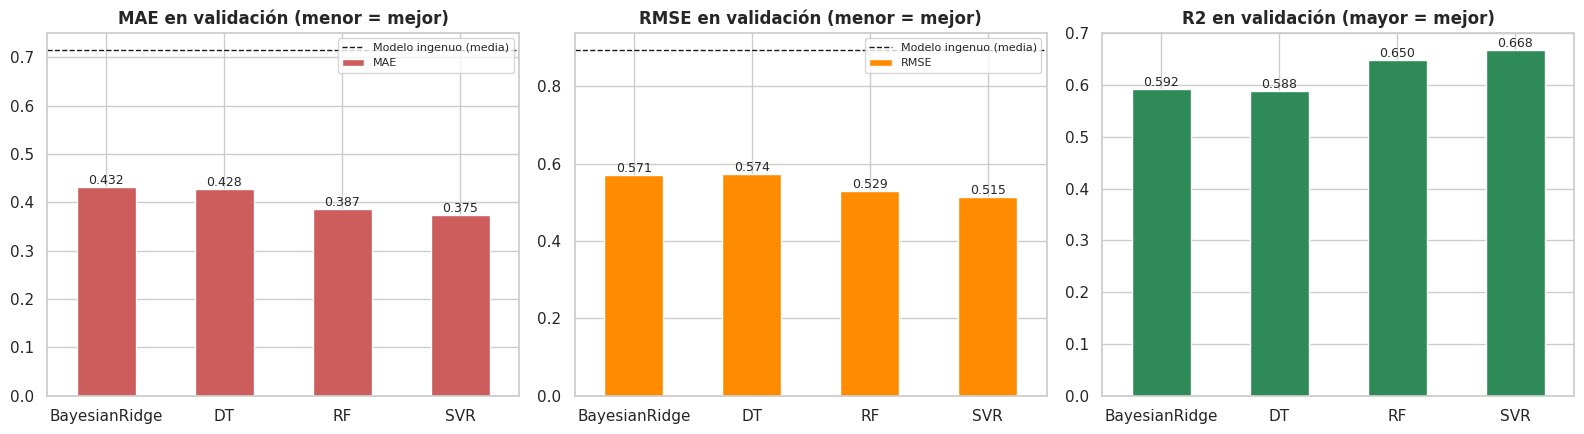

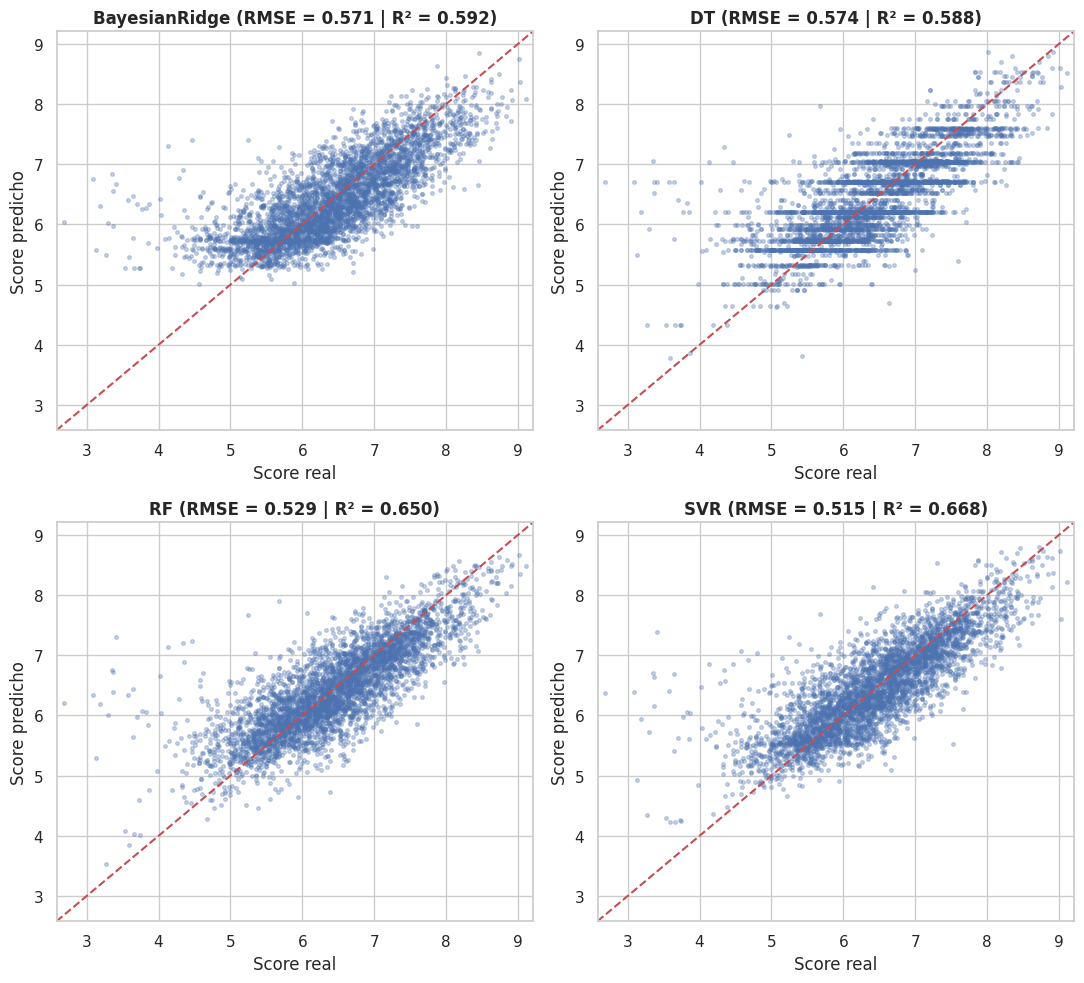

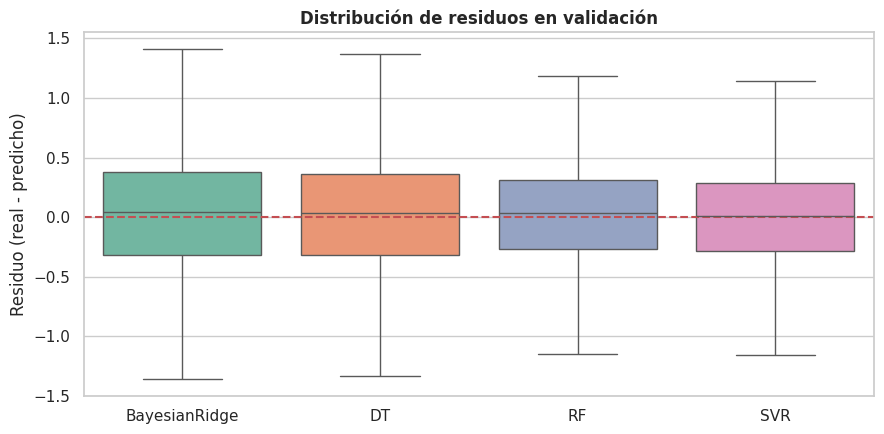

=== MAE POR CATEGORÍA REAL DE ÉXITO (validación) ===


,BayesianRidge,DT,RF,SVR
Bajo,0.742,0.692,0.610,0.590
Promedio,0.341,0.359,0.332,0.331
Alto (Éxito),0.462,0.438,0.386,0.354


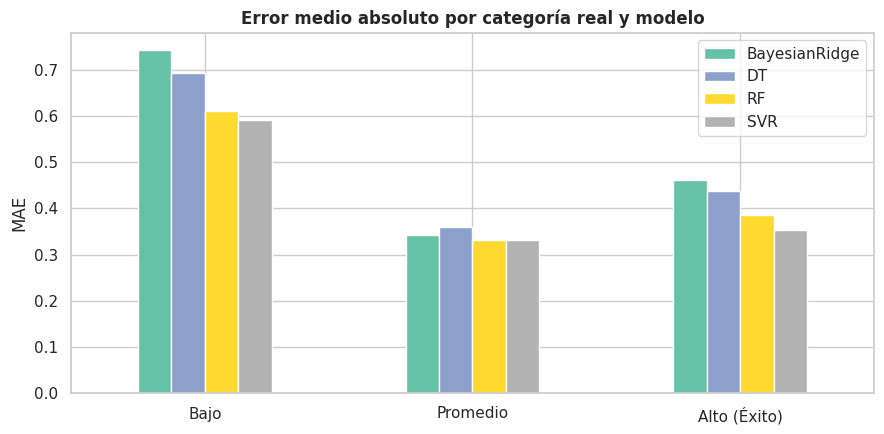

=== REGRESIÓN → CATEGORÍAS (para comparar con el Avance 2) ===


,Accuracy (discretizado),F1 macro (discretizado)
BayesianRidge,0.704,0.576
DT,0.716,0.616
RF,0.749,0.681
SVR,0.758,0.689


In [ ]:
# --- CELDA 34: Tabla comparativa y gráficas sobre validación ---
tabla_val_r = pd.DataFrame([filas_val_r[n] for n in nombres_r]).set_index('Modelo')
tabla_val_r['Brecha R2 (train-val)'] = tabla_val_r['R2 train'] - tabla_val_r['R2']
metricas_r = ['MAE', 'RMSE', 'R2']

print("=== TABLA COMPARATIVA (conjunto de validación) ===")
print(f"(Referencia — modelo ingenuo que predice la media: MAE={mae_base:.3f} | RMSE={rmse_base:.3f} | R²≈0)")
display(tabla_val_r[metricas_r + ['Brecha R2 (train-val)', 'Tiempo entrenamiento (s)']].round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m, col in zip(axes, metricas_r, ['indianred', 'darkorange', 'seagreen']):
    tabla_val_r[m].plot(kind='bar', ax=ax, rot=0, color=col)
    for i, v in enumerate(tabla_val_r[m]):
        ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    if m != 'R2':
        ax.axhline({'MAE': mae_base, 'RMSE': rmse_base}[m], color='k', linestyle='--', lw=1, label='Modelo ingenuo (media)')
        ax.legend(fontsize=8)
    ax.set_title(f"{m} en validación ({'mayor' if m == 'R2' else 'menor'} = mejor)", fontweight='bold'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

# Real vs predicho de los 4 modelos, lado a lado
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
lim = [y_val_r.min() - .1, y_val_r.max() + .1]
for ax, n in zip(axes.ravel(), nombres_r):
    ax.scatter(y_val_r, preds_val_r[n], s=7, alpha=.3)
    ax.plot(lim, lim, 'r--'); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{n} (RMSE = {tabla_val_r.loc[n, 'RMSE']:.3f} | R² = {tabla_val_r.loc[n, 'R2']:.3f})", fontweight='bold')
    ax.set_xlabel('Score real'); ax.set_ylabel('Score predicho')
plt.tight_layout(); plt.show()

# Distribución de residuos
res_df = pd.DataFrame({n: y_val_r.values - preds_val_r[n] for n in nombres_r})
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=res_df, palette='Set2', showfliers=False)
plt.axhline(0, color='r', linestyle='--')
plt.ylabel('Residuo (real - predicho)'); plt.title('Distribución de residuos en validación', fontweight='bold')
plt.tight_layout(); plt.show()

# Error por categoría real: ¿dónde falla cada modelo?
cat_real = y_val_r.apply(categorizar_exito)
mae_cat = pd.DataFrame({n: [mean_absolute_error(y_val_r[cat_real == c], preds_val_r[n][(cat_real == c).values])
                            for c in ORDEN_CLASES] for n in nombres_r}, index=ORDEN_CLASES)
print("=== MAE POR CATEGORÍA REAL DE ÉXITO (validación) ===")
display(mae_cat.round(3))
mae_cat.plot(kind='bar', figsize=(9, 4.5), rot=0, colormap='Set2')
plt.ylabel('MAE'); plt.title('Error medio absoluto por categoría real y modelo', fontweight='bold')
plt.tight_layout(); plt.show()

# Equivalencia con clasificación: score predicho -> categoría
f1_disc = {n: f1_score(cat_real, pd.Series(preds_val_r[n]).apply(categorizar_exito), average='macro',
                       labels=ORDEN_CLASES, zero_division=0) for n in nombres_r}
acc_disc = {n: accuracy_score(cat_real, pd.Series(preds_val_r[n]).apply(categorizar_exito)) for n in nombres_r}
print("=== REGRESIÓN → CATEGORÍAS (para comparar con el Avance 2) ===")
display(pd.DataFrame({'Accuracy (discretizado)': acc_disc, 'F1 macro (discretizado)': f1_disc}).round(3))

=== VALIDACIÓN CRUZADA (5 folds sobre train) ===


,MAE medio,RMSE medio,RMSE std,R2 medio,R2 std
BayesianRidge,0.426,0.559,0.012,0.602,0.012
DT,0.427,0.570,0.014,0.586,0.016
RF,0.384,0.520,0.011,0.656,0.010
SVR,0.370,0.505,0.014,0.675,0.014


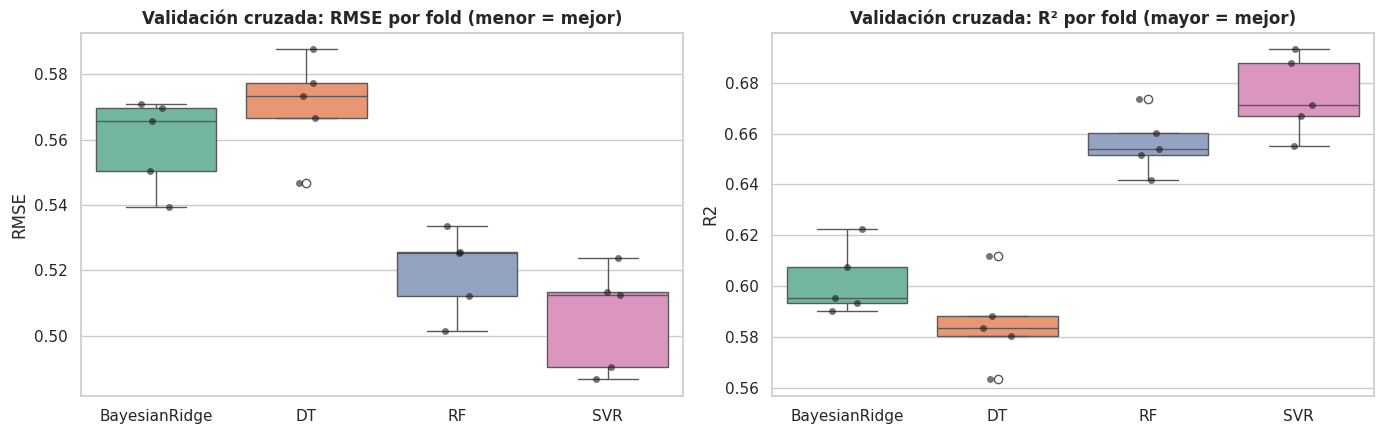

In [ ]:
# --- CELDA 35: Comparación con validación cruzada (estabilidad entre folds) ---
cv_tabla_r = pd.DataFrame({
    'MAE medio': [np.mean(cv_resultados_r[n]['test_MAE']) for n in nombres_r],
    'RMSE medio': [np.mean(cv_resultados_r[n]['test_RMSE']) for n in nombres_r],
    'RMSE std': [np.std(cv_resultados_r[n]['test_RMSE']) for n in nombres_r],
    'R2 medio': [np.mean(cv_resultados_r[n]['test_R2']) for n in nombres_r],
    'R2 std': [np.std(cv_resultados_r[n]['test_R2']) for n in nombres_r]}, index=nombres_r)
print("=== VALIDACIÓN CRUZADA (5 folds sobre train) ===")
display(cv_tabla_r.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m, tit in zip(axes, ['RMSE', 'R2'], ['RMSE por fold (menor = mejor)', 'R² por fold (mayor = mejor)']):
    datos = pd.DataFrame({n: cv_resultados_r[n][f'test_{m}'] for n in nombres_r})
    sns.boxplot(data=datos, palette='Set2', ax=ax)
    sns.stripplot(data=datos, color='k', size=5, alpha=.6, ax=ax)
    ax.set_ylabel(m); ax.set_title(f'Validación cruzada: {tit}', fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
# --- CELDA 36: Ranking y veredicto automático ---
ranking_r = pd.DataFrame({
    'MAE': tabla_val_r['MAE'].rank(ascending=True, method='min'),
    'RMSE': tabla_val_r['RMSE'].rank(ascending=True, method='min'),
    'R2': tabla_val_r['R2'].rank(ascending=False, method='min'),
    'RMSE CV (medio)': cv_tabla_r['RMSE medio'].rank(ascending=True, method='min')})
ranking_r['Ranking promedio'] = ranking_r.mean(axis=1)
print("=== RANKING (1 = mejor) ===")
display(ranking_r.sort_values('Ranking promedio').round(2))

selected_r = tabla_val_r['RMSE'].idxmin()                 # en empate: el primero de la tabla
mejor_cv_r = cv_tabla_r['RMSE medio'].idxmin()
orden_r = tabla_val_r['RMSE'].sort_values()
segundo_r = orden_r.index[1]
dif_r = orden_r.iloc[1] - orden_r.iloc[0]
std_mejor_r = cv_tabla_r.loc[selected_r, 'RMSE std']
mejora_base = (1 - orden_r.iloc[0] / rmse_base) * 100

print("\n" + "=" * 70)
print("VEREDICTO")
print("=" * 70)
print(f"• Mejor modelo por RMSE en validación: {selected_r} ({orden_r.iloc[0]:.3f}; R² = {tabla_val_r.loc[selected_r, 'R2']:.3f}).")
print(f"• Mejor modelo por RMSE medio en CV   : {mejor_cv_r} ({cv_tabla_r.loc[mejor_cv_r, 'RMSE medio']:.3f}).")
print("  → Ambos criterios " + ("coinciden." if selected_r == mejor_cv_r else "NO coinciden: la decisión es menos clara."))
print(f"• Frente al modelo ingenuo (predecir la media), reduce el RMSE en {mejora_base:.1f}%.")
print(f"• Ventaja sobre el segundo ({segundo_r}): {dif_r:.3f} de RMSE "
      + ("(menor que la desviación entre folds de CV → diferencia poco concluyente; "
         "en la práctica podrían considerarse empatados y elegirse el más simple/rápido)."
         if dif_r < std_mejor_r else "(mayor que la desviación entre folds de CV → ventaja consistente)."))
print(f"• Brecha de R² train-validación de {selected_r}: {tabla_val_r.loc[selected_r, 'Brecha R2 (train-val)']:.3f} "
      + ("→ señales de sobreajuste." if tabla_val_r.loc[selected_r, 'Brecha R2 (train-val)'] > 0.10 else "→ sin sobreajuste marcado."))
print(f"• Tiempo de entrenamiento de {selected_r}: {tabla_val_r.loc[selected_r, 'Tiempo entrenamiento (s)']:.1f} s.")
print(f"• Su categoría más difícil (mayor MAE) es '{mae_cat[selected_r].idxmax()}' (MAE = {mae_cat[selected_r].max():.3f}).")
print(f"\nModelo seleccionado: {selected_r}")

=== RANKING (1 = mejor) ===


,MAE,RMSE,R2,RMSE CV (medio),Ranking promedio
SVR,1.0,1.0,1.0,1.0,1.00
RF,2.0,2.0,2.0,2.0,2.00
BayesianRidge,4.0,3.0,3.0,3.0,3.25
DT,3.0,4.0,4.0,4.0,3.75



VEREDICTO
• Mejor modelo por RMSE en validación: SVR (0.515; R² = 0.668).
• Mejor modelo por RMSE medio en CV   : SVR (0.505).
  → Ambos criterios coinciden.
• Frente al modelo ingenuo (predecir la media), reduce el RMSE en 42.4%.
• Ventaja sobre el segundo (RF): 0.014 de RMSE (menor que la desviación entre folds de CV → diferencia poco concluyente; en la práctica podrían considerarse empatados y elegirse el más simple/rápido).
• Brecha de R² train-validación de SVR: 0.075 → sin sobreajuste marcado.
• Tiempo de entrenamiento de SVR: 20.0 s.
• Su categoría más difícil (mayor MAE) es 'Bajo' (MAE = 0.590).

Modelo seleccionado: SVR


=== RESULTADO FINAL EN TEST: SVR ===


,MAE,RMSE,R2
Modelo,,,
SVR,0.363,0.505,0.687


Modelo ingenuo en test (media): MAE = 0.724 | RMSE = 0.902


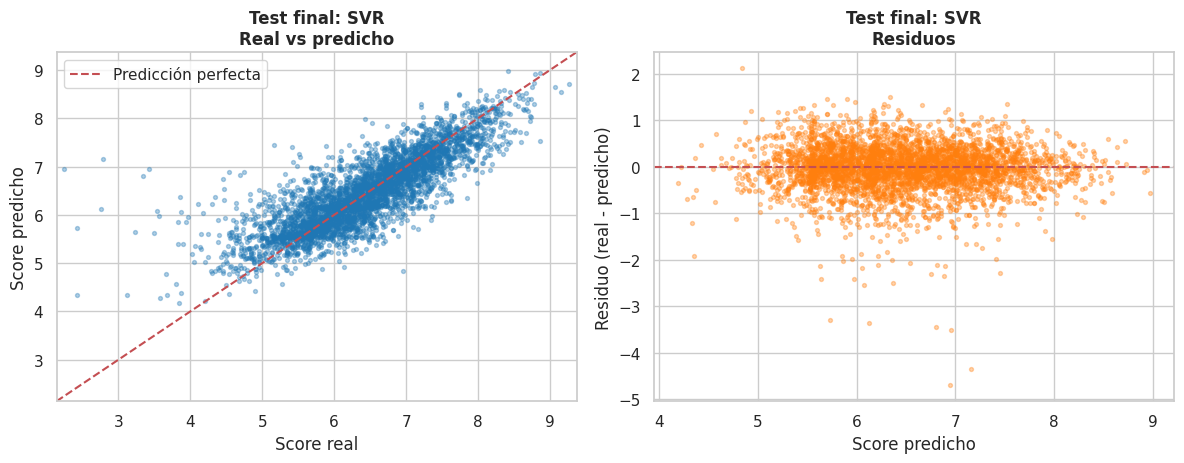


=== SVR convertido a categorías (comparable con el Avance 2) ===
              precision    recall  f1-score   support

        Bajo       0.70      0.41      0.52       576
    Promedio       0.76      0.86      0.81      2318
Alto (Éxito)       0.79      0.74      0.76      1085

    accuracy                           0.77      3979
   macro avg       0.75      0.67      0.70      3979
weighted avg       0.76      0.77      0.76      3979



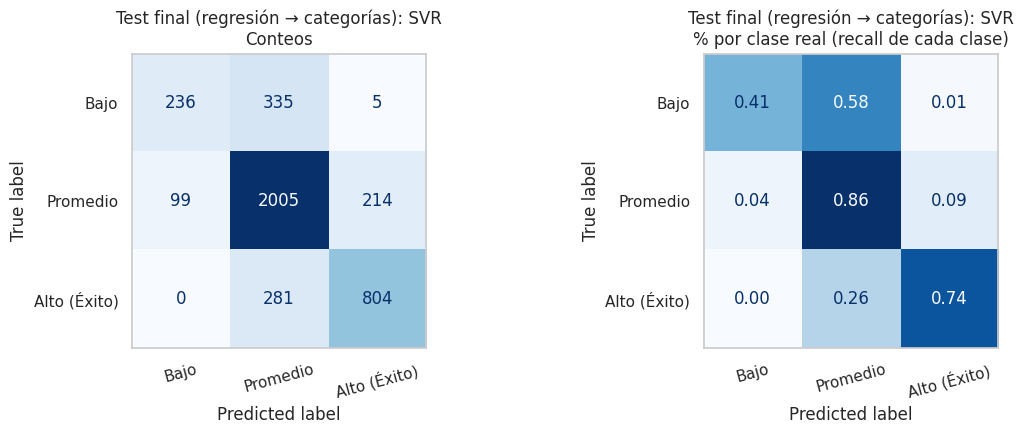

In [ ]:
# Se reentrena el modelo elegido con train + validación (80% del total).
final_model_r = clone(modelos_r[selected_r])
final_model_r.fit(X_dev, y_dev_r)
y_test_pred_r = final_model_r.predict(X_test)

print(f"=== RESULTADO FINAL EN TEST: {selected_r} ===")
res_test = pd.DataFrame([metric_row_r(selected_r, y_test_r, y_test_pred_r)]).set_index('Modelo')
display(res_test.round(3))
base_test = DummyRegressor(strategy='mean').fit(X_dev, y_dev_r).predict(X_test)
print(f"Modelo ingenuo en test (media): MAE = {mean_absolute_error(y_test_r, base_test):.3f} | RMSE = {rmse(y_test_r, base_test):.3f}")
plot_pred_r(y_test_r, y_test_pred_r, f'Test final: {selected_r}')

# Equivalencia con clasificación: ¿qué tan bien clasifica si se discretiza el score predicho?
cat_test_real = y_test_r.apply(categorizar_exito)
cat_test_pred = pd.Series(y_test_pred_r, index=y_test_r.index).apply(categorizar_exito)
print(f"\n=== {selected_r} convertido a categorías (comparable con el Avance 2) ===")
print(classification_report(cat_test_real, cat_test_pred, labels=ORDEN_CLASES, zero_division=0))
plot_cm(cat_test_real, cat_test_pred, f'Test final (regresión → categorías): {selected_r}')